# Formula 1 Podium Prediction — Milestone 1

**Task.** For every driver in every race, predict whether the driver finishes on the podium (`positionOrder <= 3`).

**Prediction cutoff.** After qualifying, before the race starts. Anything decided in or after the race (result, points, status, laps, pit stops, post-race standings) cannot be a feature.

**Unit of analysis.** One driver entering one race, so `(raceId, driverId)` must be unique in the modeling table.

| # | Section | Status |
| --- | --- | --- |
| 1 | Setup | done |
| 2 | Raw data audit (EDA before cleaning) | done |
| 3 | Data cleaning | done |
| 4 | EDA after cleaning | done |
| 5 | Data-engineering questions | done |
| 6 | Feature engineering | done |
| 7 | Data split | done |
| 8 | Feature selection | done |
| 9 | Preprocessing | done |
| 10 | Hand-off to modeling | done |
| 11 | Baseline and statistical models | to do |
| 12 | Shallow neural network | to do |
| 13 | Model comparison | to do |
| 14 | Feature-group ablation | to do |
| 15 | Explainability (XAI) | to do |
| 16 | Inference function | to do |
| 17 | Assumptions and limitations | started |

The notebook runs top to bottom with Run All, locally or on Kaggle. It uses the CSVs in `data/` or the dataset attached on Kaggle, and downloads the dataset into `data/` if neither is there. Every run overwrites the figures in `report/figures/` and the modeling table in `outputs/`.

## 1. Setup

In [1]:
import json
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

SEED = 42
KEY = ['raceId', 'driverId']       # the grain: one row per driver per race
FIG_DIR = Path('report/figures')   # figures reused in the report
OUT_DIR = Path('outputs')          # modeling table written in section 10
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

TABLES = ['circuits', 'constructor_results', 'constructor_standings', 'constructors', 'driver_standings', 'drivers',
          'lap_times', 'pit_stops', 'qualifying', 'races', 'results', 'seasons', 'sprint_results', 'status']
# latest version of the Kaggle dataset (29 Jan 2025, the author's final update): seasons 1950-2024
DATA_URL = 'https://www.kaggle.com/api/v1/datasets/download/rohanrao/formula-1-world-championship-1950-2020'


def get_data_dir():
    # 1. local copy in data/, 2. dataset attached to the Kaggle notebook, 3. download into data/
    local = Path('data')
    if (local / 'results.csv').exists():
        return local
    attached = sorted(Path('/kaggle/input').glob('**/results.csv'))
    if attached:
        return attached[0].parent
    print('Dataset not found, downloading it into data/ ...')
    local.mkdir(exist_ok=True)
    archive = local / 'f1.zip'
    urllib.request.urlretrieve(DATA_URL, archive)
    with zipfile.ZipFile(archive) as z:
        z.extractall(local)
    archive.unlink()
    return local


def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=120, bbox_inches='tight')


DATA_DIR = get_data_dir()
print('Data folder:', DATA_DIR)
print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

Data folder: data
pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1


## 2. Raw data audit (EDA before cleaning)

Every file is read as text with no missing-value parsing, so we see the values exactly as they are stored. These `raw` tables are never modified.

In [2]:
raw = {t: pd.read_csv(DATA_DIR / f'{t}.csv', dtype=str, keep_default_na=False) for t in TABLES}

race_year = raw['races'].set_index('raceId')['year'].astype(int)
inventory_rows = []
for name, t in raw.items():
    if 'raceId' in t:
        years = t['raceId'].map(race_year)
    elif 'year' in t:
        years = t['year'].astype(int)
    else:
        years = pd.Series(dtype=float)
    inventory_rows.append({'table': name, 'rows': len(t), 'columns': t.shape[1],
                           'first season': years.min(), 'last season': years.max()})
inventory = pd.DataFrame(inventory_rows).set_index('table')
inventory

,rows,columns,first season,last season
table,,,,
circuits,77,9,NaN,NaN
constructor_results,12625,5,1958.0,2024.0
constructor_standings,13391,7,1958.0,2024.0
constructors,212,5,NaN,NaN
driver_standings,34863,7,1950.0,2024.0
drivers,861,9,NaN,NaN
lap_times,589081,6,1996.0,2024.0
pit_stops,11371,7,2011.0,2024.0
qualifying,10494,9,1994.0,2024.0


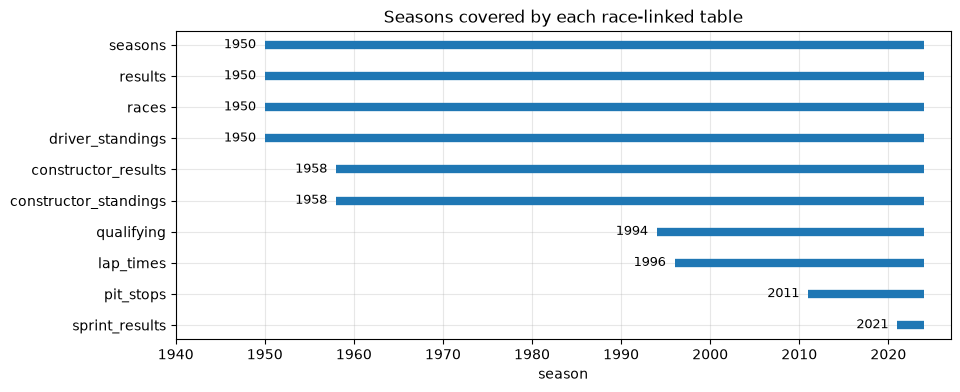

In [3]:
covered = inventory.dropna().sort_values('first season', ascending=False)
y = np.arange(len(covered))
fig, ax = plt.subplots(figsize=(10, 4))
ax.hlines(y, covered['first season'], covered['last season'], lw=6)
for i, first in enumerate(covered['first season']):
    ax.text(first - 1, i, str(int(first)), ha='right', va='center', fontsize=9)
ax.set_yticks(y, covered.index.tolist())
ax.set_xlim(1940, 2027)
ax.set_title('Seasons covered by each race-linked table')
ax.set_xlabel('season')
save_fig('table_coverage')
plt.show()

`results`, `races` and the driver standings cover 1950–2024, but `qualifying` only starts in 1994, `lap_times` in 1996, `pit_stops` in 2011 and `sprint_results` in 2021. Any feature taken from a late-starting table will be missing for the earlier seasons.

### 2.1 Missing-value sentinels

The files write a missing value as the literal text `\N`. We count it in every column, together with empty strings.

In [4]:
sentinels = []
for name, t in raw.items():
    for col in t.columns:
        n_backslash = (t[col] == '\\N').sum()
        n_empty = (t[col].str.strip() == '').sum()
        if n_backslash or n_empty:
            sentinels.append({'table': name, 'column': col, r'\N': n_backslash, 'empty': n_empty,
                              'share missing': round((n_backslash + n_empty) / len(t), 3)})
sentinels = pd.DataFrame(sentinels)
print(f'{len(sentinels)} columns contain a sentinel')

# the words pandas turns into NaN by default; if a real value looked like one, default parsing would lose it
PANDAS_NA_WORDS = ['#N/A', '#N/A N/A', '#NA', '-1.#IND', '-1.#QNAN', '-NaN', '-nan', '1.#IND', '1.#QNAN', '<NA>',
                   'N/A', 'NA', 'NULL', 'NaN', 'None', 'n/a', 'nan', 'null']
print('Values equal to one of these words, all tables:', sum(t.isin(PANDAS_NA_WORDS).sum().sum() for t in raw.values()))
sentinels

30 columns contain a sentinel
Values equal to one of these words, all tables: 0


,table,column,\N,empty,share missing
0,constructor_results,status,12608,0,0.999
1,drivers,number,802,0,0.931
2,drivers,code,757,0,0.879
3,qualifying,q1,156,0,0.015
4,qualifying,q2,4625,22,0.443
5,qualifying,q3,6819,46,0.654
6,races,time,731,0,0.650
7,races,fp1_date,1035,0,0.920
8,races,fp1_time,1057,0,0.940
9,races,fp2_date,1035,0,0.920


In [5]:
quali_raw = raw['qualifying']
empty_q2_q3 = (quali_raw['q2'] == '') | (quali_raw['q3'] == '')
print('Seasons with empty q2/q3 strings:', sorted(quali_raw.loc[empty_q2_q3, 'raceId'].map(race_year).unique().tolist()))

results_raw = raw['results']
no_grid_slot = results_raw['grid'] == '0'
no_lap = results_raw['laps'] == '0'
print("results.grid == '0':", no_grid_slot.sum())
print("results.grid == '0' and laps == '0':", (no_grid_slot & no_lap).sum())

for name, t in raw.items():
    for col in t.columns:
        padded = t[col] != t[col].str.strip()
        if padded.any():
            print(f'{name}.{col} has values with extra spaces:', t.loc[padded, col].unique().tolist())

Seasons with empty q2/q3 strings: [2023, 2024]
results.grid == '0': 1638
results.grid == '0' and laps == '0': 1566
drivers.nationality has values with extra spaces: ['Argentinian ']


The sentinels have three different meanings, which matters for how each column is used later:

- **Structurally empty**: `qualifying.q2`/`q3` are empty for drivers knocked out in an earlier session, and `results.position` is empty when a driver was not classified (the letter in `positionText` says why).
- **Not recorded in that era**: session dates and times in `races`, car numbers and codes of historical drivers.
- **Post-race fields**: `time`, `milliseconds`, `fastestLap`, `rank`. These are never features.

Two other forms of missing data are not `\N`: `q2`/`q3` use empty strings in 2023–2024 (a change in how the newest seasons were exported), and `grid = 0` marks a driver with no grid slot. One nationality also has a trailing space (`'Argentinian '`).

### 2.2 Durations stored as text

Lap times, qualifying times and pit-stop durations are strings, and not always in the same format.

In [6]:
formats = {
    'qualifying.q1': quali_raw['q1'],
    'lap_times.time': raw['lap_times']['time'],
    'pit_stops.duration': raw['pit_stops']['duration'],
}
for name, s in formats.items():
    s = s[~s.isin(['\\N', ''])]
    pattern = s.str.replace(r'\d', '9', regex=True).value_counts()
    print(name, pattern.head(4).to_dict())

qualifying.q1 {'9:99.999': 10337, '99:99.999': 1}


lap_times.time {'9:99.999': 588455, '99:99.999': 583, '9:99:99.999': 43}
pit_stops.duration {'99.999': 10854, '99:99.999': 460, '9:99.999': 57}


Qualifying times look like `1:26.572` (minutes:seconds), most pit stops like `23.456` (seconds), long pit stops (red flags) like `16:44.718`, and a few race laps under a red flag like `2:05:05.152` (hours). A single parser has to handle all three.

### 2.3 The target and the grid before cleaning

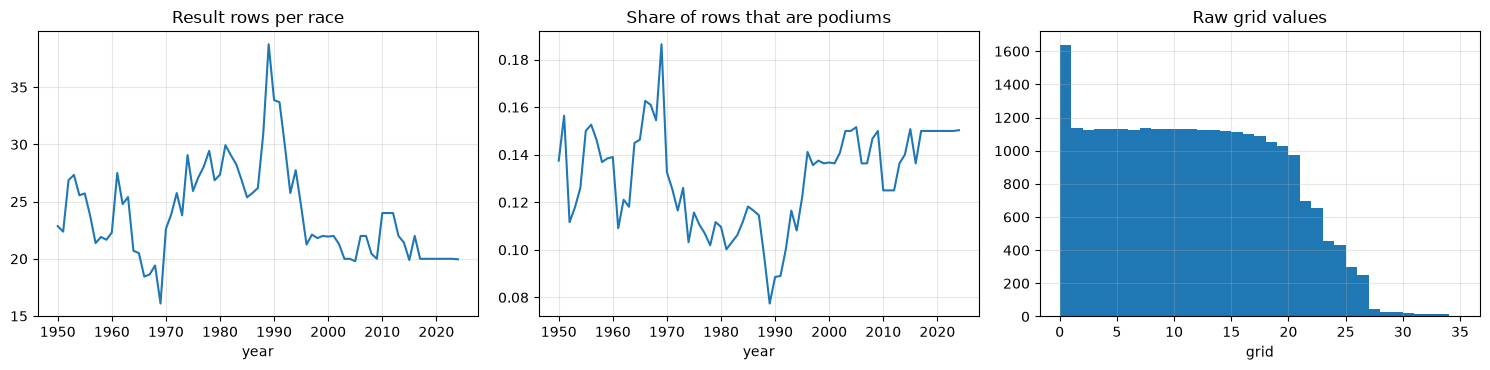

Overall podium share in the raw results: 0.127


In [7]:
raw_rows = pd.DataFrame({'raceId': results_raw['raceId'],
                         'year': results_raw['raceId'].map(race_year),
                         'podium': results_raw['positionOrder'].astype(int) <= 3,
                         'grid': results_raw['grid'].astype(int)})
per_season = raw_rows.groupby('year').agg(rows=('podium', 'size'), races=('raceId', 'nunique'), podium_share=('podium', 'mean'))
per_season['rows per race'] = per_season['rows'] / per_season['races']

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
per_season['rows per race'].plot(ax=axes[0], title='Result rows per race')
per_season['podium_share'].plot(ax=axes[1], title='Share of rows that are podiums')
axes[2].hist(raw_rows['grid'], bins=range(0, 36))
axes[2].set_title('Raw grid values')
axes[2].set_xlabel('grid')
plt.tight_layout()
save_fig('raw_target_grid')
plt.show()
print(f"Overall podium share in the raw results: {raw_rows['podium'].mean():.3f}")

- Fields were much larger before 1995 (up to ~39 entries per race), so the podium share per row was lower: three podium places shared by more entries.
- The podium share dips in the late 1970s–early 1990s, exactly when the number of rows per race peaks. Section 3.4 shows that these extra rows are entries that never started.
- `grid = 0` is a large spike (1,638 rows). It mixes drivers who never started with drivers who started from the pit lane.

**Issues found and where they are handled**

| Issue | Handled in |
| --- | --- |
| `\N` and empty strings as missing values | 3.1 |
| dates and durations stored as text, mixed duration formats | 3.1 |
| stray spaces in text | 3.1 |
| duplicate `(raceId, driverId)` rows | 3.3 |
| `grid = 0` mixes non-starters and pit-lane starts | 3.4 |
| entries that never started inflate the negative class | 3.4 |

## 3. Data cleaning

All cleaning happens on a second, typed copy of the tables (`clean`). The CSV files and the `raw` tables stay untouched.

### 3.1 Sentinels and semantic typing

- `\N` and empty strings become `NaN` while reading. `keep_default_na=False` makes sure nothing else is treated as missing; no value in the files is one of the words pandas would otherwise read as missing (`NA`, `None`, `null`, ..., counted in 2.1).
- Dates become `datetime`, durations become seconds (`float`).
- Text is stripped of extra spaces.

In [8]:
SENTINELS = ['\\N', '']
DATES = {'races': ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date'], 'drivers': ['dob']}
DURATIONS = {'qualifying': ['q1', 'q2', 'q3'], 'lap_times': ['time'], 'pit_stops': ['duration'],
             'results': ['fastestLapTime'], 'sprint_results': ['fastestLapTime']}


def to_seconds(s):
    # '23.456' -> 23.456, '1:26.572' -> 86.572, '2:05:05.152' -> 7505.152
    parts = s.str.split(':')
    return parts.map(lambda p: sum(float(x) * 60 ** i for i, x in enumerate(reversed(p))), na_action='ignore')


clean = {t: pd.read_csv(DATA_DIR / f'{t}.csv', na_values=SENTINELS, keep_default_na=False) for t in TABLES}
for table, cols in DATES.items():
    for col in cols:
        clean[table][col] = pd.to_datetime(clean[table][col])
for table, cols in DURATIONS.items():
    for col in cols:
        clean[table][col] = to_seconds(clean[table][col])
for t in clean.values():
    for col in t.select_dtypes(include=['object', 'string']).columns:
        t[col] = t[col].str.strip()

# checks
assert not any((t.astype(str) == '\\N').any().any() for t in clean.values())
laps = clean['lap_times']
print('Largest difference between parsed lap time and milliseconds column:',
      round((laps['time'] - laps['milliseconds'] / 1000).abs().max(), 6), 's')
pd.DataFrame({'raw dtype': raw['results'].dtypes.astype(str), 'clean dtype': clean['results'].dtypes.astype(str)}).T

Largest difference between parsed lap time and milliseconds column: 0.0 s


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
raw dtype,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
clean dtype,int64,int64,int64,int64,float64,int64,float64,str,int64,float64,int64,str,float64,float64,float64,float64,float64,int64


The parser is checked against the `milliseconds` column that `lap_times` already has: they agree to the millisecond on all 589,081 laps.

Not converted, on purpose: `results.time` and `sprint_results.time` hold the winner's total time but a gap (`+5.478`) for everyone else, are post-race, and `milliseconds` already has the numeric version. The clock times (`races.time`, the session times, `pit_stops.time`) are times of day, not durations, and nothing uses them.

**An impossible qualifying time.** After typing, one `q1` time is 1002.6 s (`16:42.640`) at the 1995 Japanese GP, where pole was about 98 s. No lap of Suzuka takes 16 minutes, so this is a data-entry error. Only this one time is more than 50% slower than pole (the next worst is 45%, a driver with a problem in 2023), so we set times above 150% of pole to missing.

In [9]:
quali = clean['qualifying']
q1_vs_pole = quali['q1'] / quali.groupby('raceId')['q1'].transform('min')
print(q1_vs_pole.describe(percentiles=[0.5, 0.99, 0.999]).round(3).to_dict())
slowest = quali.assign(q1_vs_pole=q1_vs_pole.round(2)).nlargest(3, 'q1_vs_pole')
display(slowest.merge(clean['races'][['raceId', 'year', 'name']], on='raceId')[['year', 'name', 'driverId', 'q1', 'q1_vs_pole']])
too_slow = q1_vs_pole > 1.5
quali.loc[too_slow, 'q1'] = np.nan

{'count': 10338.0, 'mean': 1.019, 'std': 0.093, 'min': 1.0, '50%': 1.013, '99%': 1.087, '99.9%': 1.194, 'max': 10.229}


,year,name,driverId,q1,q1_vs_pole
0,1995,Japanese Grand Prix,87,1002.640,10.23
1,2023,Saudi Arabian Grand Prix,858,128.510,1.45
2,2004,San Marino Grand Prix,47,106.299,1.33


### 3.2 Primary and foreign keys

A primary key must be unique and never missing. A foreign key must point to a row that exists in the parent table.

In [10]:
PRIMARY_KEYS = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'], 'races': ['raceId'],
    'results': ['resultId'], 'qualifying': ['qualifyId'], 'status': ['statusId'], 'seasons': ['year'],
    'driver_standings': ['driverStandingsId'], 'constructor_standings': ['constructorStandingsId'],
    'constructor_results': ['constructorResultsId'], 'sprint_results': ['resultId'],
    'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop'],
}
FOREIGN_KEYS = [
    ('races', 'circuitId', 'circuits'), ('races', 'year', 'seasons'),
    ('results', 'raceId', 'races'), ('results', 'driverId', 'drivers'), ('results', 'constructorId', 'constructors'),
    ('results', 'statusId', 'status'),
    ('qualifying', 'raceId', 'races'), ('qualifying', 'driverId', 'drivers'), ('qualifying', 'constructorId', 'constructors'),
    ('sprint_results', 'raceId', 'races'), ('sprint_results', 'driverId', 'drivers'),
    ('sprint_results', 'constructorId', 'constructors'), ('sprint_results', 'statusId', 'status'),
    ('driver_standings', 'raceId', 'races'), ('driver_standings', 'driverId', 'drivers'),
    ('constructor_standings', 'raceId', 'races'), ('constructor_standings', 'constructorId', 'constructors'),
    ('constructor_results', 'raceId', 'races'), ('constructor_results', 'constructorId', 'constructors'),
    ('lap_times', 'raceId', 'races'), ('lap_times', 'driverId', 'drivers'),
    ('pit_stops', 'raceId', 'races'), ('pit_stops', 'driverId', 'drivers'),
]


def check_primary_keys(tables, keys):
    rows = []
    for name, cols in keys.items():
        t = tables[name]
        rows.append({'table': name, 'key': ' + '.join(cols), 'rows': len(t),
                     'missing': t[cols].isna().any(axis=1).sum(), 'duplicated': t.duplicated(cols).sum()})
    return pd.DataFrame(rows)


def check_foreign_keys(tables, fks):
    rows = []
    for child, col, parent in fks:
        values = tables[child][col]
        orphans = values.notna() & ~values.isin(tables[parent][col])
        rows.append({'foreign key': f'{child}.{col} -> {parent}', 'missing': values.isna().sum(), 'orphans': orphans.sum()})
    return pd.DataFrame(rows)


pk_check = check_primary_keys(clean, PRIMARY_KEYS)
fk_check = check_foreign_keys(clean, FOREIGN_KEYS)
print('Primary-key problems:', pk_check[['missing', 'duplicated']].to_numpy().sum())
print('Foreign-key problems:', fk_check[['missing', 'orphans']].to_numpy().sum())
display(pk_check)
display(fk_check)

Primary-key problems: 0
Foreign-key problems: 0


,table,key,rows,missing,duplicated
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,results,resultId,26759,0,0
5,qualifying,qualifyId,10494,0,0
6,status,statusId,139,0,0
7,seasons,year,75,0,0
8,driver_standings,driverStandingsId,34863,0,0
9,constructor_standings,constructorStandingsId,13391,0,0


,foreign key,missing,orphans
0,races.circuitId -> circuits,0,0
1,races.year -> seasons,0,0
2,results.raceId -> races,0,0
3,results.driverId -> drivers,0,0
4,results.constructorId -> constructors,0,0
5,results.statusId -> status,0,0
6,qualifying.raceId -> races,0,0
7,qualifying.driverId -> drivers,0,0
8,qualifying.constructorId -> constructors,0,0
9,sprint_results.raceId -> races,0,0


Every primary key is unique and complete, and every foreign key reconciles. The surrogate keys are fine; the problem is the grain we need. Each table also has a *natural* key, the combination that should be unique by meaning:

In [11]:
natural_check = check_primary_keys(clean, {
    'results': KEY, 'qualifying': KEY, 'sprint_results': KEY, 'driver_standings': KEY,
    'constructor_standings': ['raceId', 'constructorId'], 'races': ['year', 'round'],
})
display(natural_check)

rounds = clean['races'].sort_values(['year', 'round']).groupby('year')['round']
assert (rounds.min() == 1).all() and (rounds.diff().dropna() == 1).all()
print('Rounds are numbered 1, 2, 3, ... without gaps in every season')


def driver_race_pairs(t):
    return set(zip(t['raceId'], t['driverId']))


result_pairs = driver_race_pairs(clean['results'])
for name in ['qualifying', 'sprint_results', 'driver_standings']:
    print(f'{name}: (raceId, driverId) pairs with no row in results = {len(driver_race_pairs(clean[name]) - result_pairs)}')

,table,key,rows,missing,duplicated
0,results,raceId + driverId,26759,0,91
1,qualifying,raceId + driverId,10494,0,0
2,sprint_results,raceId + driverId,360,0,0
3,driver_standings,raceId + driverId,34863,0,0
4,constructor_standings,raceId + constructorId,13391,0,0
5,races,year + round,1125,0,0


Rounds are numbered 1, 2, 3, ... without gaps in every season
qualifying: (raceId, driverId) pairs with no row in results = 0
sprint_results: (raceId, driverId) pairs with no row in results = 0
driver_standings: (raceId, driverId) pairs with no row in results = 8664


Round numbers have no gaps, so "the previous round" always exists after round 1 (used for the standings in 6.2). Only `results` breaks its natural key: 91 extra rows on `(raceId, driverId)`. Every qualifying and sprint row belongs to a driver who has a result in that race. `driver_standings` has 8,664 pairs with no result: the standings after a race list every driver of that season so far, including drivers who missed that race. This is how a cumulative table works, not an error; we always join it onto the driver-race rows with a left join, so it cannot add rows.

### 3.3 Duplicate driver–race rows (shared drives)

In [12]:
race_info = clean['races'][['raceId', 'year', 'round', 'date', 'name', 'circuitId']]
results = (clean['results']
           .merge(race_info, on='raceId', how='left', validate='m:1')
           .merge(clean['status'], on='statusId', how='left', validate='m:1')
           .merge(clean['drivers'][['driverId', 'surname']], on='driverId', how='left', validate='m:1'))

dups = results[results.duplicated(KEY, keep=False)].sort_values(KEY + ['resultId'])
print(f'Rows in duplicated pairs: {len(dups)} | pairs: {dups.groupby(KEY).ngroups} | extra rows: {results.duplicated(KEY).sum()}')
print('Pairs per season:', dups.drop_duplicates(KEY)['year'].value_counts().sort_index().to_dict())

cols = ['year', 'name', 'surname', 'resultId', 'number', 'grid', 'positionOrder', 'laps', 'status']
british_gp_1957 = (dups['year'] == 1957) & (dups['name'] == 'British Grand Prix') & dups['surname'].isin(['Moss', 'Brooks'])
dups.loc[british_gp_1957, cols]

Rows in duplicated pairs: 176 | pairs: 85 | extra rows: 91
Pairs per season: {1950: 4, 1951: 4, 1952: 3, 1953: 14, 1954: 16, 1955: 15, 1956: 12, 1957: 8, 1958: 3, 1960: 1, 1961: 2, 1962: 1, 1964: 1, 1978: 1}


,year,name,surname,resultId,number,grid,positionOrder,laps,status
18816,1957,British Grand Prix,Moss,18817,18.0,1,12,51,Engine
20288,1957,British Grand Prix,Moss,20291,20.0,3,1,90,Finished
18805,1957,British Grand Prix,Brooks,18806,20.0,3,1,90,Finished
20290,1957,British Grand Prix,Brooks,20293,18.0,1,12,51,Engine


All 85 pairs are from 1950–1978, almost all before 1965. They are shared drives: a driver took over a teammate's car during the race, so the driver has one row per car. The 1957 British GP above is the typical case: Moss started car #18 from pole and retired, then took over Brooks's car #20 and won. Brooks started #20 and later drove Moss's car #18. Both are officially credited with the win.

There is no column that says which car a driver started in. Two facts identify it:

1. A driver only takes over a car that someone else started, so a car that nobody else drove in that race is the driver's own car.
2. When every car the driver drove was shared, the first listed row (lowest `resultId`) is the own car: the extra shared-drive rows were appended to the table later.

We check the result: every row we do *not* keep should be a car that another driver started.

In [13]:
ordered = results.sort_values('resultId')
ordered['shared_car'] = ordered.groupby(['raceId', 'number'])['driverId'].transform('nunique') > 1
own_car = ordered.sort_values(['shared_car', 'resultId']).drop_duplicates(KEY)    # fact 1, then fact 2
other_cars = ordered.drop(own_car.index)

# check: each dropped row should be a car that another driver started
car_starters = own_car.groupby(['raceId', 'number'])['driverId'].agg(set)
started_by_other = other_cars.apply(
    lambda r: len(car_starters.get((r['raceId'], r['number']), set()) - {r['driverId']}) > 0, axis=1)
print(f'Rows not kept whose car another driver started in the same race: {started_by_other.sum()} of {len(other_cars)}')

own_ids = own_car.set_index(KEY)['resultId']
first_listed = ordered.drop_duplicates(KEY).set_index(KEY)['resultId'].reindex(own_ids.index)
fact_1_pairs = own_ids[own_ids != first_listed].index
print('Pairs where fact 1 keeps a different row than the first listed:', len(fact_1_pairs))
in_fact_1_pair = results.set_index(KEY).index.isin(fact_1_pairs)
display(results.loc[in_fact_1_pair].sort_values(KEY + ['resultId'])[cols])
other_cars.loc[~started_by_other, cols]

Rows not kept whose car another driver started in the same race: 88 of 91
Pairs where fact 1 keeps a different row than the first listed: 4


,year,name,surname,resultId,number,grid,positionOrder,laps,status
17740,1962,British Grand Prix,Greene,17741,48.0,0,22,0,Withdrew
17743,1962,British Grand Prix,Greene,17744,50.0,0,25,0,Withdrew
17961,1961,British Grand Prix,Moss,17962,26.0,20,19,56,Disqualified
17963,1961,British Grand Prix,Moss,17964,28.0,5,21,44,Brakes
19267,1954,Belgian Grand Prix,González,19268,10.0,5,4,35,+1 Lap
19275,1954,Belgian Grand Prix,González,19276,6.0,2,12,1,Engine
19918,1951,French Grand Prix,Ascari,19919,14.0,6,2,77,Finished
19934,1951,French Grand Prix,Ascari,19935,12.0,3,18,10,Gearbox


,year,name,surname,resultId,number,grid,positionOrder,laps,status
13191,1978,Italian Grand Prix,Ertl,13192,23.0,0,29,0,Did not prequalify
18519,1958,Monaco Grand Prix,Flockhart,18520,10.0,0,27,0,Did not qualify
18973,1956,French Grand Prix,da Silva Ramos,18974,8.0,16,13,40,Engine


88 of the 91 rows we do not keep are cars that another driver started in the same race. The 3 exceptions are two drivers who entered two cars and started neither (removed in 3.4) and da Silva Ramos at the 1956 French GP, who appears in two cars that nobody else drove; there we keep the first listed.

Fact 1 changes the choice in 4 pairs. In three of them (Ascari 1951, González 1954, Moss 1961) the other driver's row was appended later, so the first listed row is the car taken over; the fourth is a driver who withdrew both cars. Example: González at the 1954 Belgian GP started car #6 from grid 2, retired on lap 1 and then took over Hawthorn's car #10.

**Which row to keep?** We compared four rules on the 85 pairs:

In [14]:
dups = dups.assign(any_podium=dups.groupby(KEY)['positionOrder'].transform('min') <= 3,
                   own=dups.index.isin(own_car.index))
rules = {
    'A: own car': dups.sort_values('own', ascending=False),
    'B: best positionOrder': dups.sort_values(['positionOrder', 'resultId']),
    'C: most laps': dups.sort_values(['laps', 'resultId'], ascending=[False, True]),
}
compare_rules = []
for rule, rows in rules.items():
    kept_rows = rows.drop_duplicates(KEY).set_index(KEY)
    compare_rules.append({'rule': rule,
                          'podium labels': (kept_rows['positionOrder'] <= 3).sum(),
                          'credited podiums lost': (kept_rows['any_podium'] & (kept_rows['positionOrder'] > 3)).sum(),
                          'grid not from the own car': (kept_rows['resultId'] != own_ids.loc[kept_rows.index]).sum()})
compare_rules.append({'rule': 'D: own car, label = podium in any car',
                      'podium labels': dups.groupby(KEY)['any_podium'].first().sum(), 'credited podiums lost': 0,
                      'grid not from the own car': 0})
pd.DataFrame(compare_rules).set_index('rule')

,podium labels,credited podiums lost,grid not from the own car
rule,,,
A: own car,5,17,0
B: best positionOrder,22,0,68
C: most laps,22,0,68
"D: own car, label = podium in any car",22,0,0


- **A** keeps the right pre-race information (the car and grid slot the driver started with) but loses 17 podiums the driver is officially credited with.
- **B** and **C** keep the credited podiums but, in 68 of the 85 pairs, keep the grid slot of a car the driver did not start in. They also pick the row by looking at the race outcome.
- **D** keeps the row of the driver's own car, and labels it a podium if the driver finished on the podium in any car.

**Decision: rule D.** The features describe what was known before the start, and the label matches the official classification. In practice we keep the own-car row and replace its `positionOrder` with the driver's best `positionOrder` in that race. The choice only affects 1950–1978 races, and changes the label of 17 rows compared with rule A.

In [15]:
best_in_any_car = results.groupby(KEY)['positionOrder'].transform('min')
entries = own_car.drop(columns='shared_car')
entries['positionOrder'] = best_in_any_car.loc[entries.index]
entries['podium'] = (entries['positionOrder'] <= 3).astype(int)
assert not entries.duplicated(KEY).any()
print(f'results rows: {len(results):,} -> driver-race rows: {len(entries):,}')

results rows: 26,759 -> driver-race rows: 26,668


### 3.4 Which rows belong in the modeling table

**Entries that never started.** `grid = 0` has two meanings, which we separate with `laps`:

In [16]:
has_grid_slot = entries['grid'] > 0
completed_lap = entries['laps'] > 0
grid0 = entries[~has_grid_slot]
code = grid0['positionText'].where(~grid0['positionText'].str.isdigit(), 'number')
print(pd.crosstab(code, grid0['laps'] > 0, colnames=['completed a lap'], rownames=['positionText']))
print('Podiums among grid = 0 rows:', grid0['podium'].sum())
pit_lane_starts = entries[~has_grid_slot & completed_lap]
print(f"grid = 0 with laps > 0: {len(pit_lane_starts)} rows, seasons {pit_lane_starts['year'].min()}-{pit_lane_starts['year'].max()}")

completed a lap  False  True 
positionText                 
D                    6      0
E                    7      0
F                 1346      0
R                    2     12
W                  202      0
number               0     60
Podiums among grid = 0 rows: 0
grid = 0 with laps > 0: 72 rows, seasons 2015-2024


- `grid = 0` and no lap completed (1,563 rows): mostly `F` (failed to qualify) and `W` (withdrawn), plus a few `E`, `D`, `R`. These drivers never took the start, and none of them has a podium.
- `grid = 0` and at least one lap (72 rows, 2015–2024): pit-lane starts. They raced; most finished.

Candidate rules for the population:

In [17]:
candidates = {
    'keep everything': pd.Series(True, index=entries.index),
    'drop positionText F or W': ~entries['positionText'].isin(['F', 'W']),
    'drop grid = 0': has_grid_slot,
    'drop grid = 0 and laps = 0': has_grid_slot | completed_lap,
}
population_rules = []
for rule, keep in candidates.items():
    population_rules.append({'rule': rule, 'rows dropped': (~keep).sum(), 'podiums dropped': entries.loc[~keep, 'podium'].sum(),
                             'pit-lane starters dropped': (~has_grid_slot & completed_lap & ~keep).sum(),
                             'drivers with a grid slot dropped': (has_grid_slot & ~keep).sum(),
                             'non-starters kept': (~has_grid_slot & ~completed_lap & keep).sum()})
pd.DataFrame(population_rules).set_index('rule')

,rows dropped,podiums dropped,pit-lane starters dropped,drivers with a grid slot dropped,non-starters kept
rule,,,,,
keep everything,0,0,0,0,1563
drop positionText F or W,1701,0,0,153,15
drop grid = 0,1635,0,72,0,0
drop grid = 0 and laps = 0,1563,0,0,0,0


**Decision: keep a row if the driver had a grid slot or completed at least one lap.** It removes all 1,563 non-starters and no pit-lane starter. Dropping by letter code would keep 15 drivers who never started and drop 153 who had a grid slot; dropping every `grid = 0` would lose the 72 pit-lane starts, all in recent seasons.

Why drop non-starters at all: at the prediction cutoff (after qualifying) a driver who failed to qualify is already known not to race, so the prediction would always be "no podium". Keeping them adds easy negatives that inflate scores. Section 4.1 shows they also cause the dip in the podium share before 1995.

`laps` is a post-race column, but it is only used to recover a fact that is known before the race (whether the driver is on the starting list). It never becomes a feature.

**The Indianapolis 500 (1950–1960).** It counted for the championship, but it was a separate event with its own drivers:

In [18]:
is_indy = entries['name'] == 'Indianapolis 500'
indy_drivers = set(entries.loc[is_indy, 'driverId'])
other_drivers = set(entries.loc[~is_indy, 'driverId'])
only_indy = indy_drivers - other_drivers
nationality = clean['drivers'].set_index('driverId')['nationality']
print(f"Indianapolis 500: {is_indy.sum()} rows in {entries.loc[is_indy, 'raceId'].nunique()} races")
print(f'Drivers who raced it: {len(indy_drivers)}, of whom never raced another championship race: '
      f'{len(only_indy)} ({len(only_indy) / len(indy_drivers):.0%})')
print(f"Share of American drivers: {(entries.loc[is_indy, 'driverId'].map(nationality) == 'American').mean():.0%}")

Indianapolis 500: 381 rows in 11 races
Drivers who raced it: 107, of whom never raced another championship race: 103 (96%)
Share of American drivers: 100%


**Decision: drop the Indianapolis 500.** Almost all of its drivers never raced anywhere else, so it is a separate population inside the data, and it would add about 380 American "home" starts to question 2 (question 2 shows the answer with and without it). It is identified by race name, because the same circuit later hosted the United States GP (2000–2007).

### 3.5 Cleaning summary

In [19]:
started = has_grid_slot | completed_lap
starters = entries[started & ~is_indy].sort_values(['date', 'raceId', 'positionOrder']).reset_index(drop=True)

summary = pd.DataFrame([
    {'step': 'raw results', 'rows': len(results), 'podium rows': (results['positionOrder'] <= 3).sum()},
    {'step': 'one row per (raceId, driverId)', 'rows': len(entries), 'podium rows': entries['podium'].sum()},
    {'step': 'drop non-starters', 'rows': started.sum(), 'podium rows': entries.loc[started, 'podium'].sum()},
    {'step': 'drop Indianapolis 500', 'rows': len(starters), 'podium rows': starters['podium'].sum()},
]).set_index('step')
summary['podium share'] = (summary['podium rows'] / summary['rows']).round(3)
summary

,rows,podium rows,podium share
step,,,
raw results,26759,3397,0.127
"one row per (raceId, driverId)",26668,3395,0.127
drop non-starters,25105,3395,0.135
drop Indianapolis 500,24724,3359,0.136


## 4. EDA after cleaning

`starters` is the cleaned driver–race table: one row per `(raceId, driverId)`, only drivers who started, no Indianapolis 500.

### 4.1 What the cleaning changed

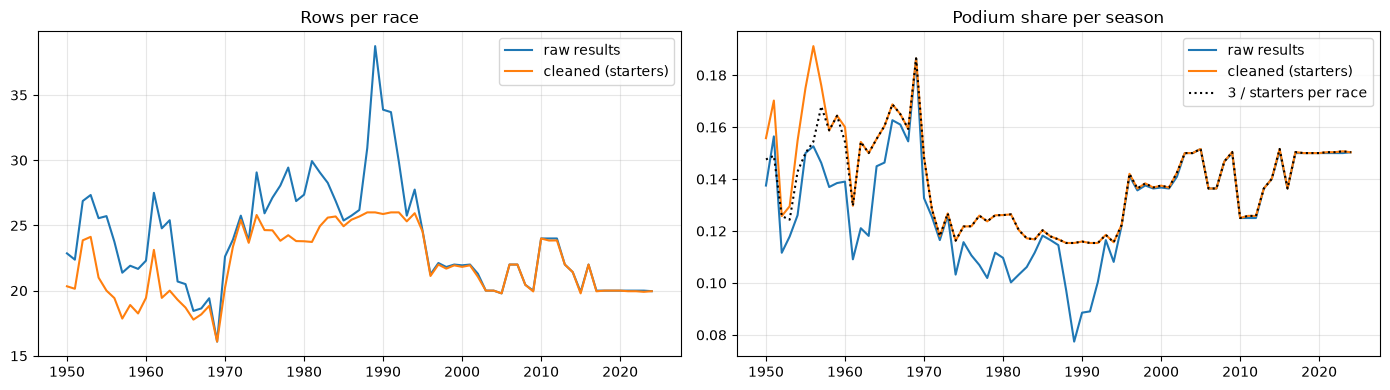

Most rows per race before / after cleaning: 38.8 / 26.0


In [20]:
raw_season = results.groupby('year').agg(rows=('raceId', 'size'), races=('raceId', 'nunique'),
                                         podium_share=('positionOrder', lambda s: (s <= 3).mean()))
clean_season = starters.groupby('year').agg(rows=('raceId', 'size'), races=('raceId', 'nunique'), podium_share=('podium', 'mean'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(raw_season.index, raw_season['rows'] / raw_season['races'], label='raw results')
axes[0].plot(clean_season.index, clean_season['rows'] / clean_season['races'], label='cleaned (starters)')
axes[0].set_title('Rows per race')
axes[0].legend()
axes[1].plot(raw_season.index, raw_season['podium_share'], label='raw results')
axes[1].plot(clean_season.index, clean_season['podium_share'], label='cleaned (starters)')
axes[1].plot(clean_season.index, 3 / (clean_season['rows'] / clean_season['races']), ls=':', c='k', label='3 / starters per race')
axes[1].set_title('Podium share per season')
axes[1].legend()
plt.tight_layout()
save_fig('cleaning_effect')
plt.show()
print('Most rows per race before / after cleaning:',
      round((raw_season['rows'] / raw_season['races']).max(), 1), '/', round((clean_season['rows'] / clean_season['races']).max(), 1))

Before cleaning, the late-1970s to early-1990s seasons had up to 38.8 rows per race; after cleaning the maximum is 26 cars, the size of a starting grid. The dip in the podium share came from the entries that never started: after cleaning, the podium share follows `3 / starters per race` in every season. In the 1950s it sits slightly above the line because a podium in a shared car credits more than one driver (rule D, 3.3). The remaining change over time is real: grids are smaller today, so a podium is a larger share of the field (about 15% now). This is why the podium rate is reported per split (section 7).

### 4.2 Starting position and podium

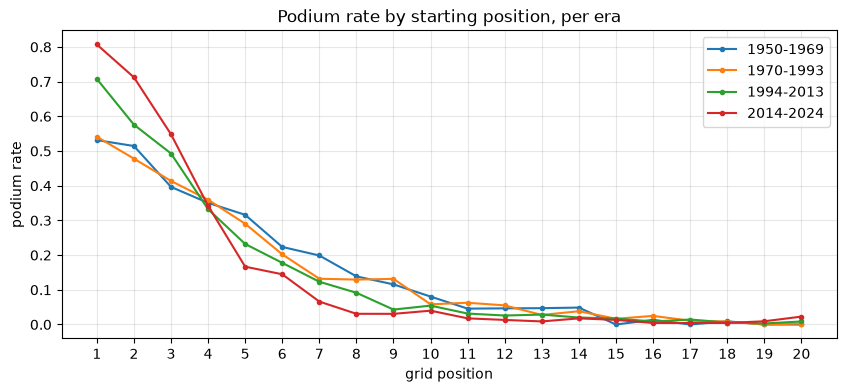

{'1950-1969': 0.53, '1970-1993': 0.54, '1994-2013': 0.71, '2014-2024': 0.81}


In [21]:
ERAS = {'1950-1969': (1950, 1969), '1970-1993': (1970, 1993), '1994-2013': (1994, 2013), '2014-2024': (2014, 2024)}
on_grid = starters[starters['grid'].between(1, 20)]
plt.figure(figsize=(10, 4))
for era, (lo, hi) in ERAS.items():
    rate = on_grid[on_grid['year'].between(lo, hi)].groupby('grid')['podium'].mean()
    plt.plot(rate.index, rate.to_numpy(), marker='o', ms=3, label=era)
plt.xticks(range(1, 21))
plt.xlabel('grid position')
plt.ylabel('podium rate')
plt.title('Podium rate by starting position, per era')
plt.legend()
save_fig('podium_by_grid')
plt.show()
pole = starters[starters['grid'] == 1]
print(pole.groupby(pd.cut(pole['year'], [1949, 1969, 1993, 2013, 2024], labels=list(ERAS)), observed=True)['podium']
      .mean().round(2).rename('podium rate from pole').to_dict())

The grid is the strongest single signal in every era: the podium rate falls steeply over the first positions and is close to zero after 10. The curve has become steeper: pole converted to a podium 53% of the time in 1950–69 and 81% since 2014, while positions 5–9 convert less often today than in the past. Cars became more reliable (4.4) and the gaps between teams more stable, so modern races follow the grid more closely. A model trained on all seasons has to cope with this drift, which is one reason the split is by time (section 7).

### 4.3 Qualifying coverage and grid vs qualifying

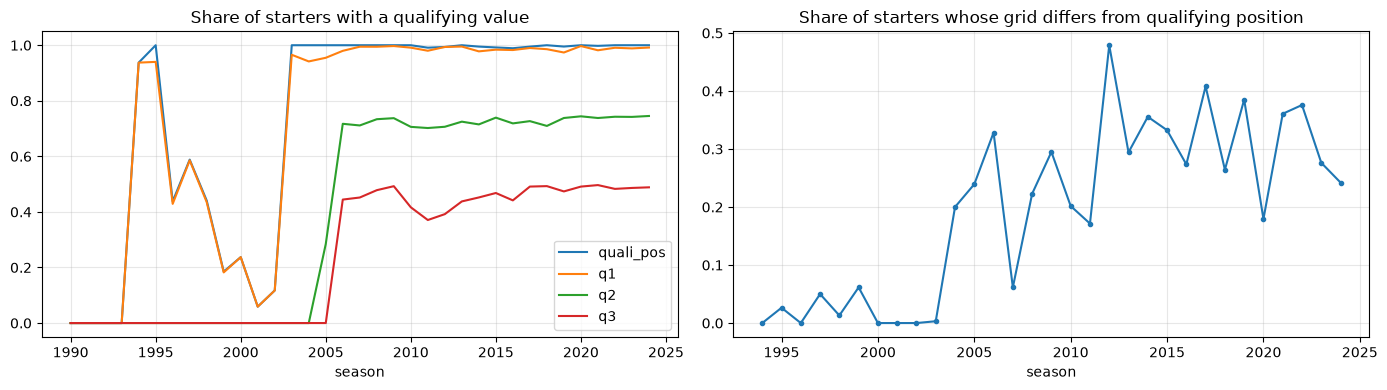

Qualifying-row coverage 1994-2005: {1994: 0.94, 1995: 1.0, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.19, 2000: 0.24, 2001: 0.06, 2002: 0.12, 2003: 1.0, 2004: 1.0, 2005: 1.0}
Grid differs from qualifying position, 2008-2024: 17% to 48% of starters


In [22]:
quali_cols = clean['qualifying'][KEY + ['position', 'q1', 'q2', 'q3']].rename(columns={'position': 'quali_pos'})
with_quali = starters.merge(quali_cols, on=KEY, how='left', validate='1:1')
coverage = with_quali.groupby('year')[['quali_pos', 'q1', 'q2', 'q3']].agg(lambda s: s.notna().mean())
both = with_quali.dropna(subset=['quali_pos'])
grid_differs = (both['grid'] != both['quali_pos']).groupby(both['year']).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
coverage.loc[1990:].plot(ax=axes[0], title='Share of starters with a qualifying value')
axes[0].set_xlabel('season')
grid_differs.plot(ax=axes[1], marker='o', ms=3, title='Share of starters whose grid differs from qualifying position')
axes[1].set_xlabel('season')
plt.tight_layout()
save_fig('qualifying_coverage')
plt.show()
print('Qualifying-row coverage 1994-2005:', coverage.loc[1994:2005, 'quali_pos'].round(2).to_dict())
print(f'Grid differs from qualifying position, 2008-2024: {grid_differs.loc[2008:].min():.0%} to {grid_differs.loc[2008:].max():.0%} of starters')

- **Coverage is not a single step.** There is no qualifying data before 1994. It is complete in 1994–1995 and from 2003 on, but only 6–59% of starters have a row in 1996–2002. Qualifying features will be missing for every row before 1994 and for most of 1996–2002 (handled in 8.3 and 9.1).
- `q2`/`q3` only exist from 2006 (knockout format). Before that the single session is stored in `q1`. Even after 2006, `q2`/`q3` are missing for drivers knocked out early, so the only time every driver has is `q1`.
- **Grid ≠ qualifying** for 17–48% of starters each season since 2008: penalties, and the places other drivers gain when someone ahead is moved back. The two are different features (question 1 and section 6).

### 4.4 Reliability over time

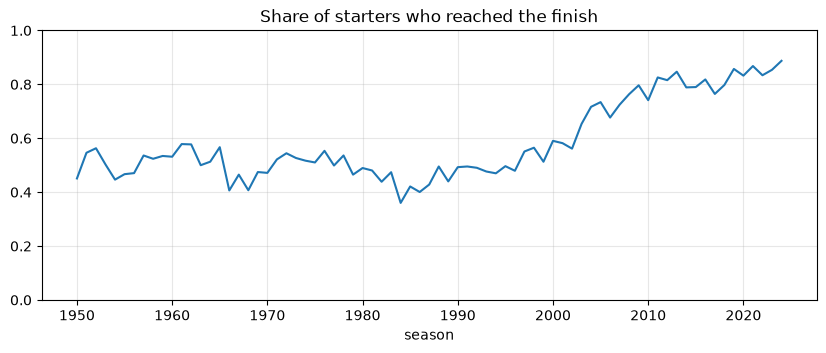

{1950: 0.5, 1960: 0.5, 1970: 0.51, 1980: 0.44, 1990: 0.5, 2000: 0.68, 2010: 0.8, 2020: 0.86}


In [23]:
FINISHED = r'^(Finished|\+\d+ Laps?)$'    # 'Finished', or classified one or more laps down
finish_rate = starters['status'].str.match(FINISHED).groupby(starters['year']).mean()
plt.figure(figsize=(10, 3.5))
plt.plot(finish_rate.index, finish_rate.to_numpy())
plt.title('Share of starters who reached the finish')
plt.xlabel('season')
plt.ylim(0, 1)
save_fig('finish_rate')
plt.show()
print(finish_rate.groupby(finish_rate.index // 10 * 10).mean().round(2).to_dict())

From the 1950s to the 1990s only about half of the starters reached the finish; in the 2010s it was 80% and in the 2020s 86%. This is why a good grid slot converted to a podium less often in the early decades (4.2). Retirement causes are grouped in question 3.

## 5. Data-engineering questions

All three answers use the cleaned `starters` table: one row per driver per race, starters only, no Indianapolis 500.

### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Joins.** `results → races → circuits` for the circuit, plus `qualifying` for the qualifying position.
**Grain.** One row = one driver starting from the front row at one race.
**Definitions.** A *front-row start* is `grid` 1 or 2 (where the car actually started, after penalties). A *front-row qualifier* is qualifying `position` 1 or 2, which only exists from 1994. Periods: 1950–2013 and 2014–2024 (hybrid era onward).
**Missingness.** `grid` is complete for all starters. The qualifying view only uses seasons with qualifying data, so it is shown separately.
**Cutoff.** Grid and qualifying are both known before the race; the podium is the outcome being described.

In [24]:
circuit_info = clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'})
q1_rows = with_quali.merge(circuit_info, on='circuitId', how='left', validate='m:1')
q1_rows['period'] = np.where(q1_rows['year'] >= 2014, '2014-2024', '1950-2013')
front_row = q1_rows[q1_rows['grid'].isin([1, 2])]
MIN_FRONT_ROW = 10


def front_row_conversion(rows, min_starts=MIN_FRONT_ROW):
    # podiums per front-row start and number of starts: one row per circuit, one column per period;
    # cells with fewer than min_starts starts are left empty
    t = rows.groupby(['circuit', 'period']).agg(starts=('podium', 'size'), podiums=('podium', 'sum'))
    t = t[t['starts'] >= min_starts]
    return (t['podiums'] / t['starts']).unstack('period'), t['starts'].unstack('period')


conversion, starts = front_row_conversion(front_row)
in_both = conversion.dropna()
print(f'Circuits with at least {MIN_FRONT_ROW} front-row starts: 1950-2013 = {conversion["1950-2013"].notna().sum()}, '
      f'2014-2024 = {conversion["2014-2024"].notna().sum()}, both periods = {len(in_both)}')
rank_corr = in_both['1950-2013'].corr(in_both['2014-2024'], method='spearman')
print(f'Spearman rank correlation between the two periods (circuits in both): {rank_corr:.2f}')
print('Overall front-row conversion:', front_row.groupby('period')['podium'].mean().round(3).to_dict())

# same comparison with a shorter "before" window, to check the answer does not come from the 1950s-80s
conversion_since_1994, _ = front_row_conversion(front_row[front_row['year'] >= 1994])
since_1994 = conversion_since_1994.dropna()
print(f'Rank correlation 1994-2013 vs 2014-2024 ({len(since_1994)} circuits): '
      f'{since_1994["1950-2013"].corr(since_1994["2014-2024"], method="spearman"):.2f}')

ranking = in_both.round(2)
for period in ['1950-2013', '2014-2024']:
    ranking[f'starts {period}'] = starts.loc[in_both.index, period].astype(int)
for period in ['1950-2013', '2014-2024']:
    ranking[f'rank {period}'] = ranking[period].rank(ascending=False, method='min').astype(int)
ranking.sort_values('rank 2014-2024')

Circuits with at least 10 front-row starts: 1950-2013 = 45, 2014-2024 = 19, both periods = 16
Spearman rank correlation between the two periods (circuits in both): -0.03
Overall front-row conversion: {'1950-2013': 0.564, '2014-2024': 0.76}
Rank correlation 1994-2013 vs 2014-2024 (15 circuits): -0.07


period,1950-2013,2014-2024,starts 1950-2013,starts 2014-2024,rank 1950-2013,rank 2014-2024
circuit,,,,,,
Suzuka Circuit,0.70,0.89,50,18,1,1
Yas Marina Circuit,0.60,0.86,10,22,6,2
Circuit de Monaco,0.50,0.85,120,20,15,3
Circuit de Barcelona-Catalunya,0.65,0.82,46,22,4,4
Circuit de Spa-Francorchamps,0.54,0.82,92,22,12,4
Shanghai International Circuit,0.65,0.79,20,14,4,6
Autódromo José Carlos Pace,0.60,0.79,62,19,6,6
Circuit Gilles Villeneuve,0.53,0.78,68,18,13,8
Silverstone Circuit,0.56,0.75,94,24,10,9


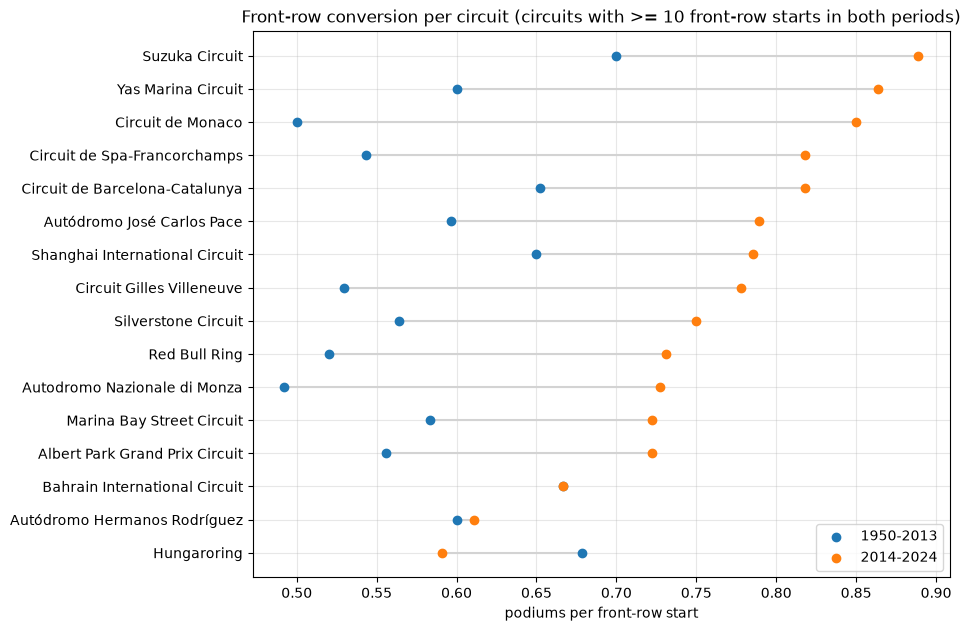

In [25]:
plot_t = in_both.sort_values('2014-2024')
y = np.arange(len(plot_t))
plt.figure(figsize=(9, 0.35 * len(plot_t) + 1.5))
plt.hlines(y, plot_t['1950-2013'], plot_t['2014-2024'], color='lightgray')
plt.scatter(plot_t['1950-2013'], y, label='1950-2013', zorder=3)
plt.scatter(plot_t['2014-2024'], y, label='2014-2024', zorder=3)
plt.yticks(y, plot_t.index)
plt.xlabel('podiums per front-row start')
plt.title('Front-row conversion per circuit (circuits with >= 10 front-row starts in both periods)')
plt.legend(loc='lower right')
save_fig('q1_front_row_conversion')
plt.show()

**Qualifying position vs grid.** From 1994, where both exist, we compare the two definitions:

In [26]:
modern = q1_rows[q1_rows['year'] >= 1994]
grid_front = modern['grid'].isin([1, 2])
quali_front = modern['quali_pos'].isin([1, 2])
definitions = []
for period, label in [('1950-2013', '1994-2013'), ('2014-2024', '2014-2024')]:
    same_period = modern['period'] == period
    for name, rows in [('front-row start (grid)', modern[same_period & grid_front]),
                       ('front-row qualifier (qualifying)', modern[same_period & quali_front])]:
        definitions.append({'period': label, 'definition': name, 'rows': len(rows), 'podium rate': round(rows['podium'].mean(), 3)})
display(pd.DataFrame(definitions))

moved_back = modern[quali_front & ~grid_front]
print(f'Front-row qualifiers who did not start from the front row: {len(moved_back)} of {quali_front.sum()}, '
      f'podium rate {moved_back["podium"].mean():.2f}')
quali_conversion, _ = front_row_conversion(modern[quali_front])
by_quali = quali_conversion['2014-2024'].dropna()
by_grid_modern = conversion['2014-2024'].reindex(by_quali.index)
print(f'2014-2024 circuit ranking, grid vs qualifying definition: Spearman {by_quali.corr(by_grid_modern, method="spearman"):.2f}')

,period,definition,rows,podium rate
0,1994-2013,front-row start (grid),698,0.642
1,1994-2013,front-row qualifier (qualifying),532,0.647
2,2014-2024,front-row start (grid),454,0.760
3,2014-2024,front-row qualifier (qualifying),454,0.740


Front-row qualifiers who did not start from the front row: 36 of 986, podium rate 0.31
2014-2024 circuit ranking, grid vs qualifying definition: Spearman 0.90


**Answer Q1.**

- **Best converters since 2014** (circuits with ≥ 10 front-row starts in both periods): Suzuka 89%, Yas Marina 86%, Monaco 85%, Barcelona and Spa 82%. **Before 2014** the same circuits were led by Suzuka 70%, Hungaroring 68%, Bahrain 67%, Barcelona and Shanghai 65%.
- **The ranking changed completely.** The rank correlation between the two periods is −0.03, i.e. knowing a circuit's rank before 2014 tells you nothing about its rank after. Hungaroring fell from 2nd to last (16th) and Monaco rose from 15th to 3rd. With the "before" period limited to 1994–2013 the correlation is −0.07, so this is not caused by the 1950s–80s.
- **Almost every circuit converts more often after 2014** (56% → 76% overall), in line with the better reliability in 4.4. Only Bahrain and Mexico stayed flat, and Hungaroring went down.
- **Qualifying vs grid.** Since 1994, 36 of 986 front-row qualifiers did not start from the front row (grid penalties), and only 31% of them reached the podium, against 64–76% for the front row overall. Averaged over all circuits the two definitions give almost the same rate (65% vs 64% before 2014, 74% vs 76% after), and the 2014–2024 circuit ranking hardly changes with the definition (rank correlation 0.90).
- **Caveat.** After 2014 each circuit has only 14–26 front-row starts, so one podium moves its rate by 4–7 points. Neighbouring ranks are not meaningfully different; the large moves (Hungaroring, Monaco) are.

### Q2. Do drivers podium more often at home, after controlling for starting position?

**Joins.** `results → drivers` (nationality) and `results → races → circuits` (country). The two use different vocabularies (`British` vs `UK`), so we map each nationality to a country by hand (table below).
**Grain.** One row = one starter at one race. *Home* = the circuit is in the driver's country.
**Control for starting position.** We compare home and away drivers *within the same grid band*, then pool the bands with the Cochran–Mantel–Haenszel (CMH) test. Each band gives a 2×2 table (home/away × podium/no podium); CMH combines them into one odds ratio and tests whether it differs from 1. An odds ratio of 1 means no home effect.
**Missingness.** Every starter has a nationality, a circuit country and a grid position.

Mapping assumptions: drivers with two nationalities (`American-Italian`, `Argentine-Italian`) take the first; `East German` maps to Germany; `Rhodesian` and `Liechtensteiner` have no circuit, so they are never home. The circuit file writes the USA both as `USA` and `United States` (Las Vegas 2023), which we merge.

,home starts,home rate,away starts,away rate
grid_band,,,,
P1,82,0.622,1034,0.648
P2-3,149,0.550,2079,0.510
P4-6,227,0.269,3115,0.261
P7-10,336,0.071,4118,0.092
P11-15,415,0.024,5126,0.030
P16+,735,0.003,7308,0.007


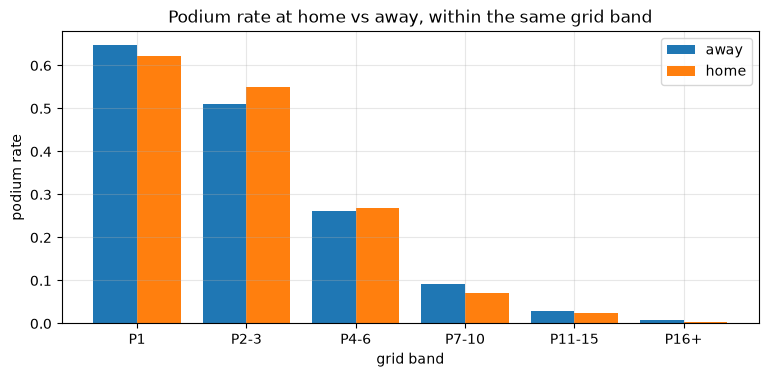

In [27]:
NATIONALITY_TO_COUNTRY = {
    'American': 'USA', 'American-Italian': 'USA', 'Argentine': 'Argentina', 'Argentinian': 'Argentina',
    'Argentine-Italian': 'Argentina', 'Australian': 'Australia', 'Austrian': 'Austria', 'Belgian': 'Belgium',
    'Brazilian': 'Brazil', 'British': 'UK', 'Canadian': 'Canada', 'Chilean': 'Chile', 'Chinese': 'China',
    'Colombian': 'Colombia', 'Czech': 'Czech Republic', 'Danish': 'Denmark', 'Dutch': 'Netherlands',
    'East German': 'Germany', 'Finnish': 'Finland', 'French': 'France', 'German': 'Germany', 'Hungarian': 'Hungary',
    'Indian': 'India', 'Indonesian': 'Indonesia', 'Irish': 'Ireland', 'Italian': 'Italy', 'Japanese': 'Japan',
    'Liechtensteiner': 'Liechtenstein', 'Malaysian': 'Malaysia', 'Mexican': 'Mexico', 'Monegasque': 'Monaco',
    'New Zealander': 'New Zealand', 'Polish': 'Poland', 'Portuguese': 'Portugal', 'Rhodesian': 'Rhodesia',
    'Russian': 'Russia', 'South African': 'South Africa', 'Spanish': 'Spain', 'Swedish': 'Sweden', 'Swiss': 'Switzerland',
    'Thai': 'Thailand', 'Uruguayan': 'Uruguay', 'Venezuelan': 'Venezuela',
}
CIRCUIT_COUNTRY_FIX = {'United States': 'USA'}
assert set(nationality) <= set(NATIONALITY_TO_COUNTRY)

driver_country = nationality.map(NATIONALITY_TO_COUNTRY)
circuit_country = clean['circuits'].set_index('circuitId')['country'].replace(CIRCUIT_COUNTRY_FIX)


def add_home(rows):
    return rows.assign(home=(rows['driverId'].map(driver_country) == rows['circuitId'].map(circuit_country)).astype(int))


GRID_BANDS = [0, 1, 3, 6, 10, 15, 99]
GRID_LABELS = ['P1', 'P2-3', 'P4-6', 'P7-10', 'P11-15', 'P16+']


def add_home_and_grid_band(rows):
    out = add_home(rows)
    out['grid_pos'] = out['grid'].where(out['grid'] > 0, 99)     # pit-lane starts go to the back
    out['grid_band'] = pd.cut(out['grid_pos'], GRID_BANDS, labels=GRID_LABELS)
    return out


def home_effect(rows, strata):
    # pooled odds ratio of podium for home vs away, within strata of starting position
    tables = []
    for _, g in rows.groupby(strata, observed=True):
        t = pd.crosstab(g['home'], g['podium']).reindex(index=[1, 0], columns=[1, 0], fill_value=0).to_numpy()
        if t[0].sum() > 0 and t[1].sum() > 0:
            tables.append(t)
    st = StratifiedTable(tables)
    low, high = st.oddsratio_pooled_confint()
    p_value = vars(st.test_null_odds())['pvalue']   # Mantel-Haenszel test of "pooled odds ratio = 1"
    return {'home starts': rows['home'].sum(), 'home podium rate': rows.loc[rows['home'] == 1, 'podium'].mean(),
            'away podium rate': rows.loc[rows['home'] == 0, 'podium'].mean(),
            'pooled odds ratio': st.oddsratio_pooled, 'CI low': low, 'CI high': high, 'p-value': p_value}


q2_rows = add_home_and_grid_band(starters)
bands = q2_rows.groupby(['grid_band', 'home'], observed=True)['podium'].agg(['mean', 'size']).unstack('home')
bands.columns = ['away rate', 'home rate', 'away starts', 'home starts']
bands = bands[['home starts', 'home rate', 'away starts', 'away rate']]
display(bands.round(3))

x = np.arange(len(bands))
plt.figure(figsize=(9, 3.8))
plt.bar(x - 0.2, bands['away rate'], width=0.4, label='away')
plt.bar(x + 0.2, bands['home rate'], width=0.4, label='home')
plt.xticks(x, bands.index)
plt.xlabel('grid band')
plt.ylabel('podium rate')
plt.title('Podium rate at home vs away, within the same grid band')
plt.legend()
save_fig('q2_home_by_grid_band')
plt.show()

The answer should not depend on how the grid is grouped or on the Indianapolis 500, so we run the same test four ways:

In [28]:
with_indy = add_home_and_grid_band(entries[started])
q2_trials = pd.DataFrame({
    'grid bands, no Indy 500 (main)': home_effect(q2_rows, 'grid_band'),
    'exact grid position, no Indy 500': home_effect(q2_rows, 'grid_pos'),
    'grid bands, with Indy 500': home_effect(with_indy, 'grid_band'),
    'grid bands, 1994-2024 only': home_effect(q2_rows[q2_rows['year'] >= 1994], 'grid_band'),
}).T
q2_trials.round(3)

,home starts,home podium rate,away podium rate,pooled odds ratio,CI low,CI high,p-value
"grid bands, no Indy 500 (main)",1944.0,0.118,0.137,0.952,0.801,1.131,0.579
"exact grid position, no Indy 500",1944.0,0.118,0.137,0.957,0.804,1.139,0.624
"grid bands, with Indy 500",2324.0,0.114,0.137,0.959,0.818,1.124,0.606
"grid bands, 1994-2024 only",594.0,0.126,0.141,0.695,0.507,0.952,0.025


**Answer Q2.**

- **No home advantage.** Without any control, home drivers podium *less* often (11.8% vs 13.7%, 1,944 home starts). Within each grid band the home and away rates are close (P1: 62% vs 65%, P2–3: 55% vs 51%, P4–6: 27% vs 26%).
- **Controlling for starting position** (CMH over grid bands): pooled odds ratio 0.95, 95% CI 0.80–1.13, p = 0.58. The interval contains 1, so there is no evidence that racing at home changes the odds of a podium for drivers who start from similar positions.
- **The answer is stable**: exact grid position instead of bands gives 0.96 (p = 0.62), and adding the Indianapolis 500 back gives 0.96 (p = 0.61).
- **1994–2024 only**: odds ratio 0.70 (CI 0.51–0.95, p = 0.025), i.e. home drivers did *worse* than away drivers from the same grid band. This is one of four variants we ran, so a p-value of 0.025 is weak evidence; we report it but do not build on it.
- The `home` flag is still tested as a model feature in 8.3.

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Joins.** `results → status` (why the race ended) `→ constructors`, and `→ races` for the season.
**Grain.** One row = one car that started one race. **Rate** = mechanical retirements ÷ race starts.
**Mechanical** means a component of the car failed. Crashes, driver causes and regulation decisions are not mechanical. The `status` table has 139 values, so we group them by hand below. Statuses that can be either a failure or the result of contact (tyre, puncture, wing, wheel, damage, the bare `Retired`) go to an *unclear* group, and we check whether counting them as mechanical changes the answer.
**Missingness.** Every result has a status. Rows whose status says the driver did not take the start (`Withdrew` with a grid slot) are not race starts, so they are left out of the denominator.
**Note.** Constructors are identified by `constructorId`, so a renamed team is a different constructor (Renault became Alpine, Toro Rosso became AlphaTauri then RB, Force India became Racing Point then Aston Martin).

In [29]:
STATUS_GROUPS = {
    'mechanical': ['Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Electronics', 'Brakes',
                   'Suspension', 'Power Unit', 'ERS', 'Turbo', 'Power loss', 'Battery', 'Spark plugs', 'Ignition', 'Injection',
                   'Magneto', 'Distributor', 'Alternator', 'Engine misfire', 'Engine fire', 'Supercharger', 'Crankshaft',
                   'Differential', 'Driveshaft', 'Halfshaft', 'Drivetrain', 'CV joint', 'Axle', 'Oil leak', 'Oil pressure',
                   'Oil pump', 'Oil pipe', 'Oil line', 'Water leak', 'Water pressure', 'Water pump', 'Water pipe', 'Overheating',
                   'Radiator', 'Cooling system', 'Fuel system', 'Fuel pressure', 'Fuel pump', 'Fuel leak', 'Fuel pipe', 'Throttle',
                   'Exhaust', 'Steering', 'Track rod', 'Wheel bearing', 'Wheel rim', 'Chassis', 'Undertray', 'Brake duct',
                   'Pneumatics', 'Heat shield fire', 'Mechanical', 'Technical', 'Launch control', 'Seat', 'Driver Seat', 'Safety belt'],
    'accident': ['Accident', 'Collision', 'Collision damage', 'Spun off', 'Fatal accident'],
    'driver': ['Physical', 'Illness', 'Driver unwell', 'Injury', 'Injured', 'Eye injury', 'Stalled'],
    'regulation': ['Disqualified', 'Excluded', 'Underweight', '107% Rule', 'Did not qualify', 'Did not prequalify'],
    'did not start': ['Withdrew', 'Safety concerns', 'Safety', 'Not restarted'],
    'unclear': ['Retired', 'Wheel', 'Wheel nut', 'Tyre', 'Puncture', 'Tyre puncture', 'Front wing', 'Rear wing', 'Broken wing',
                'Damage', 'Debris', 'Vibrations', 'Handling', 'Fire', 'Fuel', 'Out of fuel', 'Fuel rig', 'Refuelling', 'Not classified'],
}
STATUS_TO_GROUP = {s: group for group, statuses in STATUS_GROUPS.items() for s in statuses}

status_text = clean['status'].set_index('statusId')['status']
status_group = status_text.map(STATUS_TO_GROUP).mask(status_text.str.match(FINISHED), 'finished')
assert status_group.notna().all(), 'a status is not mapped'

q3_rows = starters[starters['year'].between(2014, 2024)].copy()
q3_rows['status_group'] = q3_rows['statusId'].map(status_group)
did_not_start = q3_rows['status_group'] == 'did not start'
print('Rows with a grid slot that did not take the start:', did_not_start.sum())
q3_rows = q3_rows[~did_not_start].copy()
q3_rows['period'] = np.where(q3_rows['year'] <= 2021, '2014-2021', '2022-2024')
print(q3_rows['status_group'].value_counts().to_dict())
q3_rows.loc[q3_rows['status_group'] == 'unclear', 'status'].value_counts().to_dict()

Rows with a grid slot that did not take the start: 11
{'finished': 3825, 'mechanical': 376, 'accident': 305, 'unclear': 87, 'regulation': 12, 'driver': 3}


{'Retired': 50,
 'Wheel': 11,
 'Puncture': 7,
 'Tyre': 4,
 'Rear wing': 3,
 'Front wing': 3,
 'Wheel nut': 3,
 'Vibrations': 2,
 'Damage': 2,
 'Out of fuel': 1,
 'Debris': 1}

In [30]:
constructor_name = clean['constructors'].set_index('constructorId')['name']
MIN_STARTS = 40


def mechanical_rates(rows, count_unclear=False):
    failed = rows['status_group'].eq('mechanical') | (count_unclear & rows['status_group'].eq('unclear'))
    t = rows.assign(mechanical=failed).groupby(['period', 'constructorId']).agg(starts=('mechanical', 'size'),
                                                                                 mechanical=('mechanical', 'sum')).reset_index()
    t['constructor'] = t['constructorId'].map(constructor_name)
    t['rate'] = t['mechanical'] / t['starts']
    t['ci_low'], t['ci_high'] = proportion_confint(t['mechanical'], t['starts'], method='wilson')
    return t[t['starts'] >= MIN_STARTS].sort_values(['period', 'rate'], ascending=[True, False])


q3_rates = mechanical_rates(q3_rows)
print('Mechanical retirements per start, all constructors:',
      q3_rows['status_group'].eq('mechanical').groupby(q3_rows['period']).mean().round(3).to_dict())
team_starts = q3_rows.groupby(['period', 'constructorId']).size().reset_index(name='starts')
too_few = team_starts[team_starts['starts'] < MIN_STARTS].assign(constructor=lambda t: t['constructorId'].map(constructor_name))
print(f'Left out (fewer than {MIN_STARTS} starts):', too_few[['period', 'constructor', 'starts']].to_numpy().tolist())
q3_table = {period: g.set_index('constructor')[['starts', 'mechanical', 'rate']].round(3) for period, g in q3_rates.groupby('period')}
display(pd.concat(q3_table, axis=1))

Mechanical retirements per start, all constructors: {'2014-2021': 0.091, '2022-2024': 0.058}
Left out (fewer than 40 starts): [['2014-2021', 'Marussia', 31], ['2014-2021', 'Caterham', 34]]


2014-2021                   2022-2024                  
                  starts mechanical   rate    starts mechanical   rate
constructor                                                           
Lotus F1            75.0       13.0  0.173       NaN        NaN    NaN
Toro Rosso         242.0       39.0  0.161       NaN        NaN    NaN
McLaren            318.0       43.0  0.135     136.0        5.0  0.037
Renault            200.0       27.0  0.135       NaN        NaN    NaN
Sauber             200.0       22.0  0.110      48.0        1.0  0.021
Red Bull           319.0       34.0  0.107     136.0        5.0  0.037
Racing Point        76.0        7.0  0.092       NaN        NaN    NaN
AlphaTauri          77.0        7.0  0.091      88.0        7.0  0.080
Haas F1 Team       241.0       18.0  0.075     135.0        6.0  0.044
Williams           319.0       23.0  0.072     134.0        8.0  0.060
Alpine F1 Team      44.0        3.0  0.068     136.0       15.0  0.110
Force India        199.0       13.0  0.065       NaN        NaN    NaN
Manor Marussia      77.0        4.0  0.052       NaN        NaN    NaN
Ferrari            319.0       16.0  0.050     135.0        8.0  0.059
Mercedes           320.0       12.0  0.038     136.0        6.0  0.044
Alfa Romeo         120.0        4.0  0.033      88.0       11.0  0.125
Aston Martin        44.0        1.0  0.023     133.0        5.0  0.038
RB F1 Team           NaN        NaN    NaN      48.0        2.0  0.042

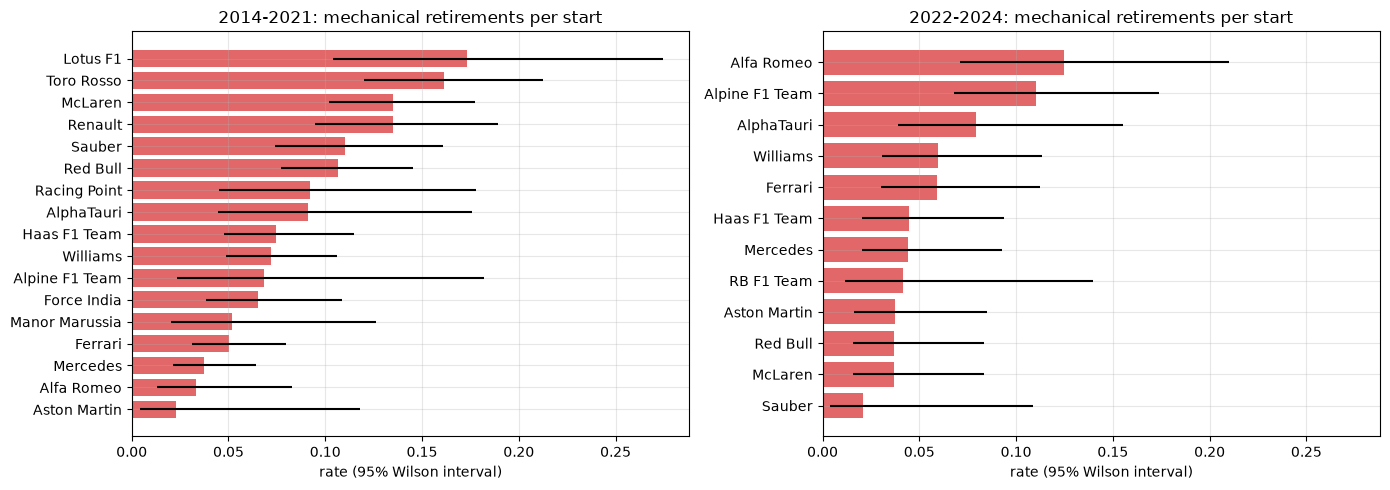

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, (period, g) in zip(axes, q3_rates.groupby('period')):
    g = g.sort_values('rate')
    ax.barh(g['constructor'], g['rate'], xerr=[g['rate'] - g['ci_low'], g['ci_high'] - g['rate']], color='tab:red', alpha=0.7)
    ax.set_title(f'{period}: mechanical retirements per start')
    ax.set_xlabel('rate (95% Wilson interval)')
plt.tight_layout()
save_fig('q3_mechanical_rate')
plt.show()

**Sensitivity.** Counting the *unclear* statuses as mechanical:

In [32]:
q3_unclear = mechanical_rates(q3_rows, count_unclear=True)
pd.DataFrame({
    period: {'top 3 (main)': ', '.join(q3_rates.loc[q3_rates['period'] == period, 'constructor'].head(3)),
             'top 3 (unclear counted)': ', '.join(q3_unclear.loc[q3_unclear['period'] == period, 'constructor'].head(3))}
    for period in ['2014-2021', '2022-2024']}).T

,top 3 (main),top 3 (unclear counted)
2014-2021,"Lotus F1, Toro Rosso, McLaren","Lotus F1, Toro Rosso, Renault"
2022-2024,"Alfa Romeo, Alpine F1 Team, AlphaTauri","Alfa Romeo, Alpine F1 Team, RB F1 Team"


**Answer Q3.**

- **2014–2021:** Lotus F1 17.3% of starts ended in a mechanical retirement (13 of 75), Toro Rosso 16.1% (39/242), McLaren 13.5% (43/318) and Renault 13.5% (27/200). Of the teams that raced all eight seasons, Mercedes was the most reliable (3.8%).
- **2022–2024:** Alfa Romeo 12.5% (11/88), Alpine 11.0% (15/136), AlphaTauri 8.0% (7/88). Most teams are between 2% and 6%.
- **Mechanical retirements became rarer overall** (9.1% of starts in 2014–2021, 5.8% in 2022–2024). McLaren (13.5% → 3.7%) and Red Bull (10.7% → 3.7%) improved the most.
- **Sensitivity:** counting the unclear statuses as mechanical, the leaders stay the same: Lotus F1 and Toro Rosso, then Renault, in 2014–2021; Alfa Romeo and Alpine, then RB, in 2022–2024.
- **Caveats:** the intervals are wide (about ±4–5 points with ~130 starts), so teams in the middle cannot be ranked against each other. Renamed teams count separately: Alfa Romeo (2022–23) and Sauber (2024) are the same team, 12 of 136 starts (8.8%) together.

## 6. Feature engineering

### 6.1 Leakage screen

A column can be a feature only if its value is known after qualifying and before the start.

| Table | Columns | Known before the start? | Use |
| --- | --- | --- | --- |
| `results` | `grid` | yes, the starting grid | feature |
| `results` | `positionOrder`, `position`, `positionText`, `points`, `laps`, `time`, `milliseconds`, `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed`, `statusId` | no, race outcome | target only (`positionOrder`); from *earlier* races through form features |
| `qualifying` | `position`, `q1`, `q2`, `q3` | yes | features |
| `driver_standings`, `constructor_standings` | `position`, `points`, `wins` | only the standings after the *previous* round | shifted by one round |
| `constructor_results` | `points` | no for the current race | not used (the standings already hold it) |
| `lap_times`, `pit_stops` | all | no, recorded during the race | not used |
| `sprint_results` | all | yes (sprint runs before the race) | not used, see 6.4 |
| `races`, `drivers`, `circuits` | date, round, date of birth, nationality, country | yes | ordering, age, home race |

### 6.2 Features

Each feature belongs to a group; the groups are reused by the ablation in section 14.

| Group | Feature | Meaning |
| --- | --- | --- |
| grid | `grid_pos` | starting position; pit-lane start = back of the field |
| grid | `pit_lane_start` | 1 if the driver starts from the pit lane |
| qualifying | `quali_pos` | qualifying position |
| qualifying | `q1_gap_pct` | % slower than the fastest Q1 time of the race (the only session every driver runs) |
| qualifying | `grid_minus_quali` | places lost (+) or gained (−) between qualifying and the grid |
| standings | `drv_standing`, `con_standing` | championship position after the previous round |
| standings | `drv_points_share`, `con_points_share` | points after the previous round ÷ leader's points (scale-free across points systems) |
| standings | `drv_points`, `con_points`, `drv_wins` | raw values, kept only for the comparison in 8.3 |
| driver form | `drv_podium_last` | podium rate over the driver's last *n* starts |
| driver form | `drv_finish_last` | average finishing percentile over the last *n* starts (0 = won, 1 = last) |
| driver form | `drv_career_podium` | podium rate over all earlier starts |
| constructor form | `con_podium_last` | share of the team's last *n* races with a car on the podium |
| constructor form | `con_finish_last` | average best finishing percentile of the team over its last *n* races |
| experience | `drv_starts`, `driver_age` | earlier starts; age on race day |
| context | `field_size`, `home` | starters in the race; circuit in the driver's country |

Form features only look backwards: for each driver (or team) the rows are ordered by race date, shifted by one race, and then averaged, so the current race is never included. We start with a window of the last 5 races; section 8.3 compares 3, 5, 10 and 20 and rebuilds the table with the chosen window.

In [33]:
def past_mean(rows, by, col, n=None):
    # mean of `col` over the previous n rows of the same driver/team (all previous rows if n is None)
    shifted = rows.groupby(by)[col].shift(1)
    window = shifted.groupby(rows[by])
    if n is None:
        return window.transform(lambda s: s.expanding().mean())
    return window.transform(lambda s: s.rolling(n, min_periods=1).mean())


def standings_before(rows):
    # standings after the previous round of the same season (round 1 has none)
    prev = clean['races'][['raceId', 'year', 'round']].assign(round=lambda r: r['round'] + 1).rename(columns={'raceId': 'prev_raceId'})
    rows = rows.merge(prev, on=['year', 'round'], how='left', validate='m:1')
    ds = clean['driver_standings'].rename(columns={'raceId': 'prev_raceId', 'position': 'drv_standing', 'points': 'drv_points', 'wins': 'drv_wins'})
    cs = clean['constructor_standings'].rename(columns={'raceId': 'prev_raceId', 'position': 'con_standing', 'points': 'con_points'})
    rows = rows.merge(ds[['prev_raceId', 'driverId', 'drv_standing', 'drv_points', 'drv_wins']], on=['prev_raceId', 'driverId'], how='left', validate='m:1')
    rows = rows.merge(cs[['prev_raceId', 'constructorId', 'con_standing', 'con_points']], on=['prev_raceId', 'constructorId'], how='left', validate='m:1')
    rows['drv_points_share'] = rows['drv_points'] / rows.groupby('prev_raceId')['drv_points'].transform('max').replace(0, np.nan)
    rows['con_points_share'] = rows['con_points'] / rows.groupby('prev_raceId')['con_points'].transform('max').replace(0, np.nan)
    return rows.drop(columns='prev_raceId')


def build_features(rows, n_form, history=None):
    # rows: one row per driver-race; history: past results used for form (default: rows itself)
    X = rows[KEY + ['constructorId', 'circuitId', 'year', 'round', 'date', 'grid', 'podium']].copy()

    # grid
    X['field_size'] = X.groupby('raceId')['raceId'].transform('size')
    X['pit_lane_start'] = (X['grid'] == 0).astype(int)
    X['grid_pos'] = X['grid'].where(X['grid'] > 0, X['field_size'])

    # qualifying
    q = clean['qualifying'][KEY + ['position', 'q1']].rename(columns={'position': 'quali_pos'})
    q['q1_gap_pct'] = 100 * (q['q1'] / q.groupby('raceId')['q1'].transform('min') - 1)
    X = X.merge(q[KEY + ['quali_pos', 'q1_gap_pct']], on=KEY, how='left', validate='1:1')
    X['grid_minus_quali'] = X['grid_pos'] - X['quali_pos']

    # standings before the race
    X = standings_before(X)

    # driver form, from earlier starts only
    past = (rows if history is None else history)[KEY + ['constructorId', 'date', 'positionOrder', 'podium']]
    past = past.sort_values(['date', 'raceId']).copy()
    past['finish_pct'] = past.groupby('raceId')['positionOrder'].rank(pct=True)
    past['drv_podium_last'] = past_mean(past, 'driverId', 'podium', n_form)
    past['drv_finish_last'] = past_mean(past, 'driverId', 'finish_pct', n_form)
    past['drv_career_podium'] = past_mean(past, 'driverId', 'podium')
    past['drv_starts'] = past.groupby('driverId').cumcount()
    X = X.merge(past[KEY + ['drv_podium_last', 'drv_finish_last', 'drv_career_podium', 'drv_starts']], on=KEY, how='left', validate='1:1')

    # constructor form: one row per team per race, then the same backward window
    team = past.groupby(['constructorId', 'raceId']).agg(date=('date', 'first'), podium=('podium', 'max'),
                                                         finish_pct=('finish_pct', 'min')).reset_index()
    team = team.sort_values(['date', 'raceId'])
    team['con_podium_last'] = past_mean(team, 'constructorId', 'podium', n_form)
    team['con_finish_last'] = past_mean(team, 'constructorId', 'finish_pct', n_form)
    X = X.merge(team[['constructorId', 'raceId', 'con_podium_last', 'con_finish_last']], on=['constructorId', 'raceId'],
                how='left', validate='m:1')

    # experience and context
    X['driver_age'] = (X['date'] - X['driverId'].map(clean['drivers'].set_index('driverId')['dob'])).dt.days / 365.25
    X = add_home(X)
    return X


ALL_FEATURES = ['grid_pos', 'pit_lane_start', 'quali_pos', 'q1_gap_pct', 'grid_minus_quali',
                'drv_standing', 'con_standing', 'drv_points_share', 'con_points_share', 'drv_points', 'con_points', 'drv_wins',
                'drv_podium_last', 'drv_finish_last', 'drv_career_podium', 'con_podium_last', 'con_finish_last',
                'drv_starts', 'driver_age', 'field_size', 'home']
features = build_features(starters, n_form=5)
print(features.shape)
features[ALL_FEATURES].describe().T.round(2)

(24724, 30)


,count,mean,std,min,25%,50%,75%,max
grid_pos,24724.0,11.81,6.75,1.00,6.00,12.00,17.00,34.00
pit_lane_start,24724.0,0.00,0.05,0.00,0.00,0.00,0.00,1.00
quali_pos,10478.0,11.19,6.25,1.00,6.00,11.00,16.00,26.00
q1_gap_pct,10322.0,1.85,1.93,0.00,0.71,1.34,2.36,44.78
grid_minus_quali,10478.0,0.01,1.52,-9.00,0.00,0.00,0.00,23.00
drv_standing,21798.0,12.86,8.95,1.00,6.00,12.00,18.00,102.00
con_standing,21795.0,6.10,3.63,1.00,3.00,6.00,9.00,20.00
drv_points_share,21798.0,0.22,0.29,0.00,0.00,0.08,0.33,1.00
con_points_share,21795.0,0.30,0.34,0.00,0.02,0.14,0.50,1.00
drv_points,21798.0,20.54,44.19,0.00,0.00,4.00,19.00,549.00


### 6.3 Leakage checks

Three automatic checks that no feature uses the race it describes:

In [34]:
def check_no_leakage(X, rows, n_form):
    # X: the feature table built from `rows` (sorted by date)
    first_start = X.sort_values(['date', 'raceId']).groupby('driverId').head(1)
    assert first_start[['drv_podium_last', 'drv_finish_last', 'drv_career_podium']].isna().all().all()
    assert (first_start['drv_starts'] == 0).all()
    assert X.loc[X['round'] == 1, ['drv_standing', 'con_standing']].isna().all().all()
    for _, row in X.sample(300, random_state=SEED).iterrows():
        past = rows[(rows['driverId'] == row['driverId']) & (rows['date'] < row['date'])].tail(n_form)
        expected = past['podium'].mean() if len(past) else np.nan
        assert np.isclose(expected, row['drv_podium_last'], equal_nan=True)
    print(f'Leakage checks passed (form window = {n_form} races)')


check_no_leakage(features, starters, n_form=5)

Leakage checks passed (form window = 5 races)


1. A driver's first start has no form and `drv_starts = 0`.
2. Round 1 of every season has no standings (nothing has been raced yet).
3. For 300 random rows, the driver's podium rate over the last *n* starts is recomputed by hand from strictly earlier races and matches.

The checks run again on the final features in 8.3.

### 6.4 Sprint results

The sprint is held before the Sunday race, so its result is pre-race information. We still leave it out:

In [35]:
sprint_races = clean['sprint_results']['raceId'].unique()
print(features.assign(has_sprint=features['raceId'].isin(sprint_races))
      .groupby(pd.cut(features['year'], [1949, 2019, 2021, 2024], labels=['train (<=2019)', 'val (2020-21)', 'test (2022-24)']), observed=True)
      ['has_sprint'].agg(['sum', 'mean']).rename(columns={'sum': 'rows with a sprint', 'mean': 'share'}))

                rows with a sprint     share
year                                        
train (<=2019)                   0  0.000000
val (2020-21)                   59  0.075738
test (2022-24)                 299  0.220501


Sprints start in 2021, so no training row has one: a sprint feature would be missing for 100% of the training data and the model could not learn what it means. In 2021–2022 the sprint result also *set* the Sunday grid, so its information is already in `grid_pos`.

## 7. Data split

We split by season, as suggested in the F1 introduction: **train ≤ 2019, validation 2020–2021, test 2022–2024.**

- The model is used to predict future races from past ones, so it must never train on seasons after the ones it is evaluated on.
- A race always stays in one split. The three podium places of a race depend on each other, so splitting a race's drivers would leak information.
- Section 4.2 showed that the grid-to-podium relationship drifts across eras. A time split measures how well the model handles that drift. The test set is the new 2022 ground-effect era, an honest but harder test.

In [36]:
def split_of(year):
    return np.select([year <= 2019, year <= 2021], ['train', 'val'], 'test')


features['split'] = split_of(features['year'])
assert features.groupby('raceId')['split'].nunique().max() == 1
split_summary = features.groupby('split').agg(seasons=('year', lambda y: f'{y.min()}-{y.max()}'), races=('raceId', 'nunique'),
                                              rows=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean'))
split_summary.loc[['train', 'val', 'test']].round(3)

,seasons,races,rows,podiums,podium_rate
split,,,,,
train,1950-2019,1007,22589,3038,0.134
val,2020-2021,39,779,117,0.150
test,2022-2024,68,1356,204,0.150


The podium rate is 13% in train and 15% in validation and test: the training seasons include the larger fields of the past (section 4.1). Threshold-free metrics (ROC-AUC, PR-AUC) are not affected by this; an F1 threshold must be chosen on validation, not train.

### 7.1 How data decisions are evaluated

Every decision in sections 8 and 9 is tested with the same small experiment, which never touches the test seasons:

- **Model:** logistic regression with median imputation, missing-value indicators and standard scaling (the preprocessing is compared with alternatives in 9.1). For the decisions that could depend on the model, we also run a gradient-boosted tree model (`HistGradientBoostingClassifier`).
- **Validation windows:** the official validation split is only 39 races (779 rows, 117 podiums), so one window is noisy. We repeat the experiment on three consecutive two-season windows: train on all seasons before 2016 → score 2016–17, before 2018 → 2018–19, before 2020 → 2020–21 (the official validation split).
- **Metric:** PR-AUC (average precision), because podiums are the rare class (13–15%) and PR-AUC focuses on ranking the podium finishers above everyone else. ROC-AUC is reported next to it.
- **Decision rule:** an option replaces the reference only if its mean PR-AUC is higher by more than the noise level (measured below) *and* it is better in at least 2 of the 3 windows. Otherwise the options are tied, and we keep the simpler one or decide on domain grounds, and say so.

In [37]:
WINDOWS = [(2016, 2017), (2018, 2019), (2020, 2021)]
WINDOW_COLS = [f'{lo}-{hi}' for lo, hi in WINDOWS]


def make_lr():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), LogisticRegression(max_iter=2000))


def make_hgb():
    # fixed number of trees: no internal random validation split, so the result does not depend on a seed
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, early_stopping=False, random_state=SEED)


def score_windows(data, feature_list, model=make_lr, start=1950):
    scores, aucs = {}, []
    for lo, hi in WINDOWS:
        train = data[data['year'].between(start, lo - 1)]
        valid = data[data['year'].between(lo, hi)]
        proba = model().fit(train[feature_list], train['podium']).predict_proba(valid[feature_list])[:, 1]
        scores[f'{lo}-{hi}'] = average_precision_score(valid['podium'], proba)
        aucs.append(roc_auc_score(valid['podium'], proba))
    scores['mean PR-AUC'] = np.mean(list(scores.values()))
    scores['mean ROC-AUC'] = np.mean(aucs)
    return pd.Series(scores)


def windows_won(new, ref):
    # in how many validation windows `new` has a higher PR-AUC than `ref`
    return int((new[WINDOW_COLS] > ref[WINDOW_COLS]).sum())


def compare(scores):
    # one row per option; every option is compared with the first row (the reference)
    t = pd.DataFrame(scores).T.round(4)
    t['change in mean PR-AUC'] = t['mean PR-AUC'] - t['mean PR-AUC'].iloc[0]
    t['better windows'] = ['reference'] + [f'{windows_won(row, t.iloc[0])}/3' for _, row in t.iloc[1:].iterrows()]
    return t


def passes(new, ref, noise):
    return new['mean PR-AUC'] - ref['mean PR-AUC'] > noise and windows_won(new, ref) >= 2


# the features used by the trials until the selection in 8.3 (obvious duplicates already left out, see 8.2)
CANDIDATES = ['grid_pos', 'pit_lane_start', 'quali_pos', 'q1_gap_pct', 'drv_standing', 'con_standing',
              'drv_podium_last', 'drv_finish_last', 'con_podium_last', 'con_finish_last', 'drv_starts', 'driver_age', 'field_size']

**How large is a difference that means nothing?** We drop a random 1% of the training rows, score again, and repeat five times. Nothing meaningful changed, so the spread of these scores is the noise level. A difference must be larger than twice its standard deviation to count.

In [38]:
NOISE, noise_runs = {}, {}
for label, model in [('LR', make_lr), ('HGB', make_hgb)]:
    runs = []
    for seed in range(5):
        dropped = features[features['year'] <= 2019].sample(frac=0.01, random_state=seed).index
        runs.append(score_windows(features.drop(dropped), CANDIDATES, model)['mean PR-AUC'])
    noise_runs[label] = runs
    NOISE[label] = 2 * np.std(runs)
noise_table = pd.DataFrame(noise_runs, index=[f'run {i}' for i in range(5)]).T
noise_table['noise level (2 x std)'] = pd.Series(NOISE)
noise_table.round(4)

,run 0,run 1,run 2,run 3,run 4,noise level (2 x std)
LR,0.7223,0.7199,0.7177,0.719,0.7251,0.0052
HGB,0.7135,0.7226,0.7076,0.709,0.7135,0.0105


Dropping 1% of the training rows moves the LR mean PR-AUC between 0.718 and 0.725 (noise level 0.005) and the tree model between 0.708 and 0.723 (noise level 0.011). These are the thresholds of the decision rule. They also say how to read every table below: a difference in the third decimal is not evidence.

The tree model's scores also depend slightly on the scikit-learn version. We ran this notebook with scikit-learn 1.9 (the numbers quoted in the text) and 1.5: every decision in sections 8 and 9 came out the same. The tree model's mean PR-AUCs moved by up to 0.009 (single windows by up to 0.035) and its noise level was 0.005 instead of 0.011. Logistic regression gave identical numbers.

**Would a random split give different numbers?** We scored the same validation rows (a random half of 2020–21) with a model trained on seasons ≤ 2019 (time split) and with a model trained on the same number of rows drawn at random from every season, including 2022–24 and the other half of 2020–21 (random split).

In [39]:
val_rows = features[features['year'].between(2020, 2021)]
train_time = features[features['year'] <= 2019]
random_vs_time = []
for seed in range(3):
    held_out = val_rows.sample(frac=0.5, random_state=seed)
    pool = features.drop(held_out.index)
    train_random = pool.sample(n=len(train_time), random_state=seed)
    scores = {}
    for name, train in [('time split', train_time), ('random split', train_random)]:
        proba = make_lr().fit(train[CANDIDATES], train['podium']).predict_proba(held_out[CANDIDATES])[:, 1]
        scores[name] = average_precision_score(held_out['podium'], proba)
    random_vs_time.append({'seed': seed, **scores})
pd.DataFrame(random_vs_time).set_index('seed').round(4)

,time split,random split
seed,,
0,0.6750,0.6776
1,0.7275,0.7257
2,0.7818,0.7805


The two splits give almost the same PR-AUC on the same rows, and neither wins every time. A random split would not inflate the score much here, because the features describe the situation (grid, standings, form) rather than who the driver is. The time split is chosen because it is the only valid setup for predicting future races, not because it scores differently.

## 8. Feature selection

Evidence is computed on the **training split only** (≤ 2019), so validation and test stay untouched.

### 8.1 How each feature relates to the podium

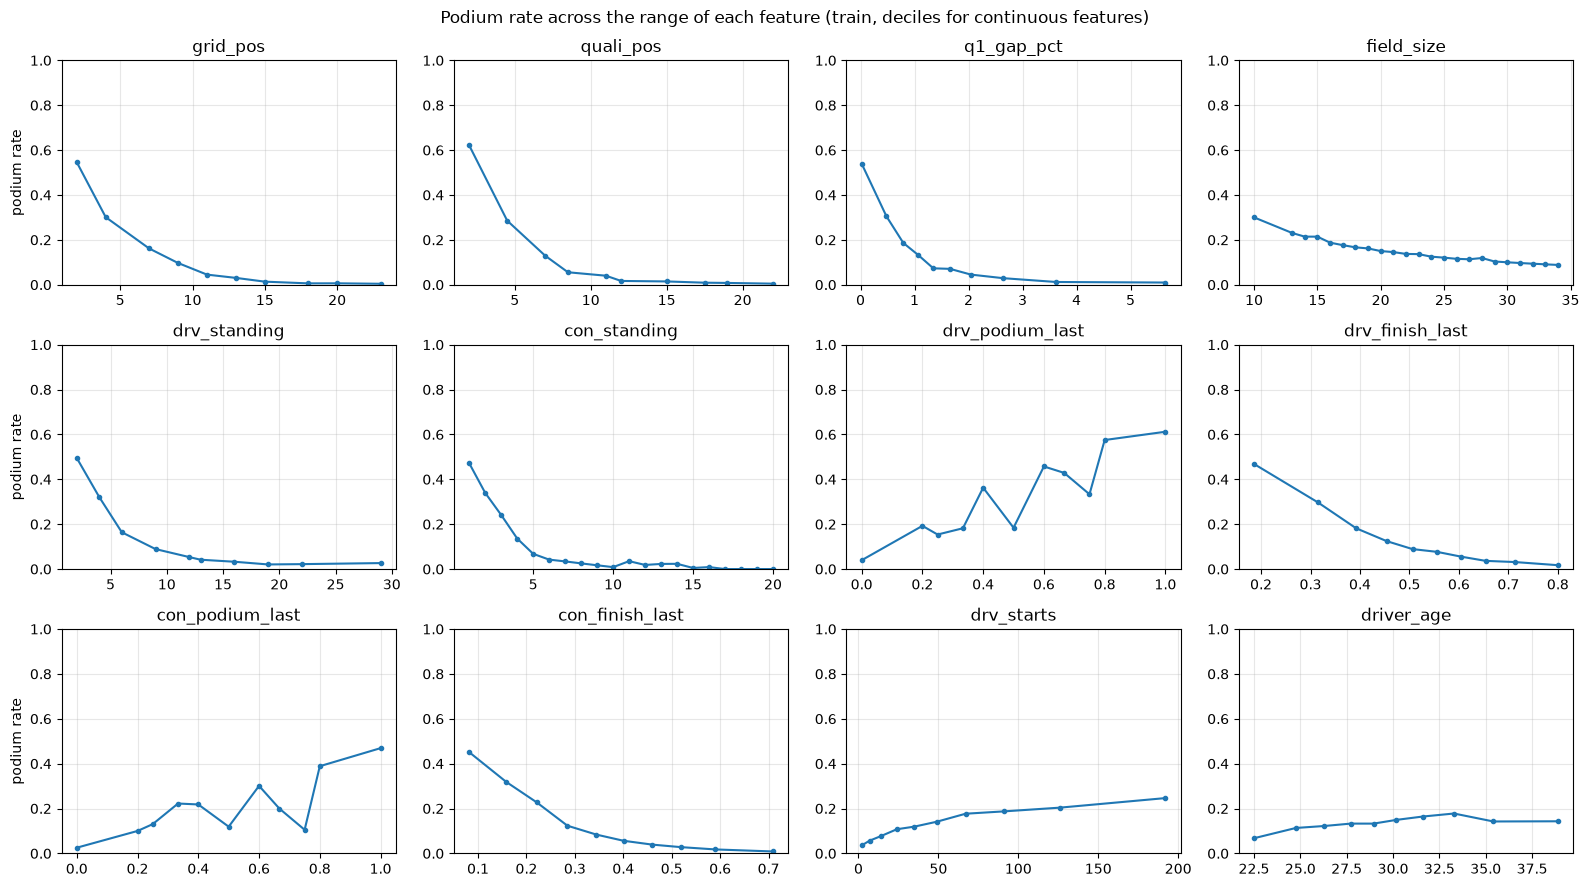

In [40]:
train_rows = features[features['split'] == 'train']
SHOW = ['grid_pos', 'quali_pos', 'q1_gap_pct', 'field_size', 'drv_standing', 'con_standing',
        'drv_podium_last', 'drv_finish_last', 'con_podium_last', 'con_finish_last', 'drv_starts', 'driver_age']
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), SHOW):
    d = train_rows[[col, 'podium']].dropna()
    if d[col].nunique() > 25:
        decile = pd.qcut(d[col], 10, labels=False, duplicates='drop')
        rate = d.groupby(decile)['podium'].mean()
        x = d.groupby(decile)[col].median()
    else:
        rate = d.groupby(col)['podium'].mean()
        x = rate.index
    ax.plot(x, rate.values, marker='o', ms=3)
    ax.set_title(col)
    ax.set_ylim(0, 1)
for ax in axes[:, 0]:
    ax.set_ylabel('podium rate')
plt.suptitle('Podium rate across the range of each feature (train, deciles for continuous features)')
plt.tight_layout()
save_fig('feature_effects')
plt.show()

In [41]:
def univariate_auc(rows, col):
    d = rows[[col, 'podium']].dropna()
    auc = roc_auc_score(d['podium'], d[col])
    return max(auc, 1 - auc), ('higher = more podiums' if auc >= 0.5 else 'lower = more podiums')


evidence = []
for c in ALL_FEATURES:
    auc, direction = univariate_auc(train_rows, c)
    evidence.append({'feature': c, 'ROC-AUC alone': auc, 'direction': direction, 'coverage (train)': train_rows[c].notna().mean()})
pd.DataFrame(evidence).set_index('feature').sort_values('ROC-AUC alone', ascending=False).round(3)

,ROC-AUC alone,direction,coverage (train)
feature,,,
quali_pos,0.906,lower = more podiums,0.369
grid_pos,0.884,lower = more podiums,1.000
drv_standing,0.837,lower = more podiums,0.875
con_points_share,0.837,higher = more podiums,0.875
drv_points_share,0.831,higher = more podiums,0.875
q1_gap_pct,0.830,lower = more podiums,0.363
con_standing,0.829,lower = more podiums,0.875
con_podium_last,0.818,higher = more podiums,0.988
con_finish_last,0.818,lower = more podiums,0.988


`ROC-AUC alone` ranks the training rows by one feature at a time (0.5 = no signal, 1 = perfect). Qualifying and grid position are the strongest single signals (0.91 and 0.88), then standings, the qualifying gap and team form (0.82–0.84), then driver form (0.79–0.81). `drv_starts` is weak (0.66), and `driver_age`, `field_size`, `grid_minus_quali`, `home` and `pit_lane_start` carry almost no signal on their own (≤ 0.56). The plots show why `driver_age` is weak: the podium rate rises until the early thirties and then falls, so higher or lower age alone does not rank drivers. Note that the qualifying features are only observed for 37% of the training rows (section 4.3).

### 8.2 Redundancy

Pairs of features that carry almost the same information (Spearman |ρ| ≥ 0.9 on train):

In [42]:
rho = train_rows[ALL_FEATURES].corr(method='spearman').abs()
pairs = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
pairs[pairs >= 0.9].sort_values(ascending=False).round(3).rename('|spearman|').to_frame()

,,|spearman|
grid_pos,quali_pos,0.976
drv_points_share,drv_points,0.933
con_standing,con_points_share,0.924
drv_standing,drv_points_share,0.921


- `grid_pos` / `quali_pos` (0.98): we keep both on purpose. They differ exactly when a penalty moves a driver (section 4.3, question 1), and that difference is information.
- `drv_standing` / `drv_points_share` / `drv_points` and the constructor equivalents: the same quantity in different units. 8.3 chooses one.
- `grid_minus_quali` is `grid_pos − quali_pos` by construction, so with both of those kept it adds nothing new. We drop it.

### 8.3 Trials

**Standings: which representation?** The points system changed several times (a win was worth 8–10 points before 2010 and 25 after), so raw points are not comparable across seasons. Base features for this trial: grid + qualifying.

In [43]:
BASE = ['grid_pos', 'pit_lane_start', 'quali_pos', 'q1_gap_pct']
compare({
    'standing position': score_windows(features, BASE + ['drv_standing', 'con_standing']),
    'raw points': score_windows(features, BASE + ['drv_points', 'con_points']),
    'points share of leader': score_windows(features, BASE + ['drv_points_share', 'con_points_share']),
    'position + share + wins': score_windows(features, BASE + ['drv_standing', 'con_standing', 'drv_points_share', 'con_points_share', 'drv_wins']),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
standing position,0.7512,0.7164,0.7118,0.7265,0.9356,0.0000,reference
raw points,0.7129,0.6822,0.7080,0.7010,0.9293,-0.0255,0/3
points share of leader,0.7469,0.7094,0.7177,0.7246,0.9356,-0.0019,1/3
position + share + wins,0.7489,0.7132,0.7286,0.7302,0.9364,0.0037,1/3


Raw points are worse in every window (−0.026, far beyond the noise), which confirms the scale problem. Points share alone and position + share + wins are within the noise of the position (−0.002 and +0.004, better in 1 of 3 windows), so they are ties. **Decision: standing position** (`drv_standing`, `con_standing`), the simplest scale-free option.

**What if the standings were not shifted?** Using the standings *after* the race (the leak 6.1 warns about):

In [44]:
drv_after_race = clean['driver_standings'][KEY + ['position']].rename(columns={'position': 'drv_standing'})
con_after_race = clean['constructor_standings'][['raceId', 'constructorId', 'position']].rename(columns={'position': 'con_standing'})
leaky = (features.drop(columns=['drv_standing', 'con_standing'])
         .merge(drv_after_race, on=KEY, how='left')
         .merge(con_after_race, on=['raceId', 'constructorId'], how='left'))
compare({
    'standings before the race (correct)': score_windows(features, BASE + ['drv_standing', 'con_standing']),
    'standings after the race (leak)': score_windows(leaky, BASE + ['drv_standing', 'con_standing']),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
standings before the race (correct),0.7512,0.7164,0.7118,0.7265,0.9356,0.0000,reference
standings after the race (leak),0.7816,0.7721,0.7713,0.7750,0.9519,0.0485,3/3


The leaky version scores higher in every window (+0.048 mean PR-AUC). A leak looks like an improvement, which is why leakage is ruled out by the screen in 6.1 and the checks in 6.3 and never by the score.

**Form window.** How many past races should the form features average? The same candidate feature set, with `n` changed:

In [45]:
form_tables = {n: build_features(starters, n_form=n) for n in [3, 5, 10, 20]}
for label, model in [('LR', make_lr), ('HGB', make_hgb)]:
    display(compare({f'{label}, last {n} races': score_windows(table, CANDIDATES, model) for n, table in form_tables.items()}))

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, last 3 races",0.7472,0.7164,0.7153,0.7263,0.9369,0.0000,reference
"LR, last 5 races",0.7389,0.6977,0.7224,0.7197,0.9375,-0.0066,1/3
"LR, last 10 races",0.7250,0.7129,0.7251,0.7210,0.9394,-0.0053,1/3
"LR, last 20 races",0.7270,0.7150,0.7396,0.7272,0.9403,0.0009,1/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, last 3 races",0.7435,0.7420,0.6743,0.7199,0.9327,0.0000,reference
"HGB, last 5 races",0.7367,0.7264,0.6898,0.7177,0.9345,-0.0022,1/3
"HGB, last 10 races",0.7610,0.7258,0.6918,0.7262,0.9379,0.0063,2/3
"HGB, last 20 races",0.7083,0.7115,0.7275,0.7157,0.9350,-0.0042,1/3


No window length beats the last 3 races by more than the noise level: the best alternatives are 20 races for LR (+0.001) and 10 races for the tree model (+0.006, below its noise level of 0.011). The last 3 races do beat the last 5 for LR (+0.007 in 2 of 3 windows). Apart from that the window length is a **tie**.

How much each window length overlaps with the season-to-date standings and the career podium rate (Spearman |ρ| on train):

In [46]:
overlap = {}
for n, table in form_tables.items():
    tr = table[table['year'] <= 2019]
    overlap[f'last {n} races'] = {
        'drv_podium_last vs drv_career_podium': tr['drv_podium_last'].corr(tr['drv_career_podium'], method='spearman'),
        'drv_podium_last vs drv_standing': abs(tr['drv_podium_last'].corr(tr['drv_standing'], method='spearman')),
        'con_podium_last vs con_standing': abs(tr['con_podium_last'].corr(tr['con_standing'], method='spearman')),
    }
pd.DataFrame(overlap).round(3)

,last 3 races,last 5 races,last 10 races,last 20 races
drv_podium_last vs drv_career_podium,0.618,0.693,0.783,0.863
drv_podium_last vs drv_standing,0.686,0.730,0.746,0.726
con_podium_last vs con_standing,0.764,0.798,0.811,0.788


The longer the window, the more `drv_podium_last` repeats what the career podium rate and the standings already say (|ρ| with the career rate 0.62 for 3 races, 0.86 for 20). **Decision: the last 3 races.** It is never beaten, and it adds the most information the other features do not already have (recent changes such as an upgrade or a new car).

**Feature groups, added one at a time (forward selection).** We start from the grid group and try the next group on top of the groups kept so far. A group is kept if it passes the decision rule (7.1, including the noise level) for at least one of the two models: the models in sections 11–12 are of both kinds, and a group that only helps a non-linear model is still useful there. The order follows the strength of the single-feature evidence in 8.1.

In [47]:
N_FORM_FINAL = 3
features = build_features(starters, n_form=N_FORM_FINAL)
features['split'] = split_of(features['year'])
check_no_leakage(features, starters, n_form=N_FORM_FINAL)
GROUP_ORDER = {
    'grid': ['grid_pos', 'pit_lane_start'],
    'qualifying': ['quali_pos', 'q1_gap_pct'],
    'standings': ['drv_standing', 'con_standing'],
    'driver form': ['drv_podium_last', 'drv_finish_last', 'drv_career_podium'],
    'constructor form': ['con_podium_last', 'con_finish_last'],
    'experience': ['drv_starts', 'driver_age'],
    'context': ['field_size'],
    'home': ['home'],
}
MODELS = {'LR': make_lr, 'HGB': make_hgb}
kept = ['grid']
current = {label: score_windows(features, GROUP_ORDER['grid'], model) for label, model in MODELS.items()}
selection = []
for group, cols in list(GROUP_ORDER.items())[1:]:
    base_cols = [c for g in kept for c in GROUP_ORDER[g]]
    new = {label: score_windows(features, base_cols + cols, model) for label, model in MODELS.items()}
    keep_group = any(passes(new[label], current[label], NOISE[label]) for label in MODELS)
    selection.append({
        'group tried': group,
        'LR before': current['LR']['mean PR-AUC'], 'LR with group': new['LR']['mean PR-AUC'],
        'LR better windows': f"{windows_won(new['LR'], current['LR'])}/3",
        'HGB before': current['HGB']['mean PR-AUC'], 'HGB with group': new['HGB']['mean PR-AUC'],
        'HGB better windows': f"{windows_won(new['HGB'], current['HGB'])}/3",
        'kept': keep_group,
    })
    if keep_group:
        kept.append(group)
        current = new
pd.DataFrame(selection).set_index('group tried').round(4)

Leakage checks passed (form window = 3 races)


,LR before,LR with group,LR better windows,HGB before,HGB with group,HGB better windows,kept
group tried,,,,,,,
qualifying,0.6782,0.7157,3/3,0.6783,0.6666,1/3,True
standings,0.7157,0.7265,2/3,0.6666,0.7151,3/3,True
driver form,0.7265,0.7295,1/3,0.7151,0.7369,2/3,True
constructor form,0.7295,0.7305,2/3,0.7369,0.7335,1/3,False
experience,0.7295,0.7300,1/3,0.7369,0.7240,1/3,False
context,0.7295,0.7296,2/3,0.7369,0.7370,1/3,False
home,0.7295,0.7295,0/3,0.7369,0.7390,2/3,False


- **Kept: grid, qualifying, standings, driver form.** Each clears the noise level by at least a factor of two for one model: qualifying +0.038 for LR (3/3 windows), standings +0.011 for LR and +0.049 for the tree model (3/3), driver form +0.022 for the tree model (2/3).
- **Dropped: constructor form** (+0.001 for LR, −0.003 for the tree model). The team's strength is already in the model through `con_standing`; the team's last 3 races add nothing on top of it.
- **Dropped: experience, context (`field_size`) and home.** None of them raises either model's mean PR-AUC by more than 0.002, far below the noise level (experience even lowers the tree model by 0.013). This agrees with 8.1 (almost no signal on their own) and, for `home`, with question 2.
- The tree model gets *worse* when qualifying is added (−0.012): qualifying is missing for 63% of the training rows, so the tree partly learns which rows have qualifying data. The group is kept because it passes clearly for LR (+0.038 in all three windows), and the later groups lift the tree model above its grid-only score.

**Training window.** Qualifying data only exist from 1994 and are complete from 2003. Should the model learn only from seasons where the qualifying features are observed, or from all seasons with those features imputed?

In [48]:
FEATURE_GROUPS = {g: GROUP_ORDER[g] for g in kept}
SELECTED = [c for cols in FEATURE_GROUPS.values() for c in cols]
FORM_FINAL = [c for g in ['driver form', 'constructor form'] for c in FEATURE_GROUPS.get(g, [])]
print('Selected groups:', kept)
for label, model in [('LR', make_lr), ('HGB', make_hgb)]:
    display(compare({f'{label}, from {start} ({features["year"].between(start, 2019).sum():,} train rows)':
                     score_windows(features, SELECTED, model, start=start) for start in [1950, 1981, 1994, 2003, 2010]}))

Selected groups: ['grid', 'qualifying', 'standings', 'driver form']


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"LR, from 1950 (22,589 train rows)",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"LR, from 1981 (15,415 train rows)",0.7360,0.7088,0.7329,0.7259,0.9378,-0.0036,0/3
"LR, from 1994 (10,165 train rows)",0.7340,0.7047,0.7267,0.7218,0.9379,-0.0077,0/3
"LR, from 2003 (6,821 train rows)",0.7266,0.7031,0.7339,0.7212,0.9391,-0.0083,1/3
"LR, from 2010 (4,288 train rows)",0.7292,0.7052,0.7212,0.7185,0.9388,-0.0110,0/3


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"HGB, from 1950 (22,589 train rows)",0.7657,0.7402,0.7047,0.7369,0.9385,0.0000,reference
"HGB, from 1981 (15,415 train rows)",0.7494,0.7254,0.7137,0.7295,0.9365,-0.0074,1/3
"HGB, from 1994 (10,165 train rows)",0.7334,0.6975,0.7009,0.7106,0.9346,-0.0263,0/3
"HGB, from 2003 (6,821 train rows)",0.6787,0.7118,0.6907,0.6937,0.9308,-0.0432,0/3
"HGB, from 2010 (4,288 train rows)",0.6366,0.5912,0.7129,0.6469,0.9229,-0.0900,1/3


Every shorter window scores lower for both models, and starting from 1994 or later is worse by more than the noise level (LR −0.008 to −0.011, tree model −0.026 to −0.090). The old seasons still teach how grid, standings and form relate to the podium, and the missing-value indicators let the model treat the imputed qualifying values separately. **Decision: train on all seasons, 1950–2019.**

### 8.4 Selected features

| Group | Feature | Evidence | Known before the start because |
| --- | --- | --- | --- |
| grid | `grid_pos` | strongest signal in every era (4.2); ROC-AUC alone 0.88 | the starting grid is fixed before the start |
| grid | `pit_lane_start` | needed to encode `grid = 0` (9.1) | pit-lane starts are on the starting list |
| qualifying | `quali_pos` | ROC-AUC alone 0.91; with `q1_gap_pct` +0.038 PR-AUC on top of the grid (LR) | qualifying ends before the race |
| qualifying | `q1_gap_pct` | ROC-AUC alone 0.83; measures pace, not only order | same |
| standings | `drv_standing`, `con_standing` | 0.84 / 0.83 alone; +0.011 (LR), +0.049 (tree model) | standings after the previous round (6.3 checks round 1 is empty) |
| driver form | `drv_podium_last`, `drv_finish_last`, `drv_career_podium` | 0.79–0.81 alone; +0.022 (tree model) | earlier races only (6.3 recomputes 300 rows by hand) |

Not used: `grid_minus_quali` (8.2), points share / raw points / wins (8.3), constructor form, experience, `field_size` and `home` (8.3), sprint results (6.4).

## 9. Preprocessing

### 9.1 Trials

**Missing values.** Missing in the selected features (train): qualifying features (no data before 1994 and gaps in 1996–2002), standings (round 1 and a driver's first race of the season) and form (first start).

In [49]:
train_rows = features[features['split'] == 'train']
print(train_rows[SELECTED].isna().mean().round(3)[lambda s: s > 0].to_dict())


def make_lr_with(imputer):
    return lambda: make_pipeline(imputer, StandardScaler(), LogisticRegression(max_iter=2000))


domain = features.copy()
domain['quali_pos'] = domain['quali_pos'].fillna(domain['grid_pos'])   # no qualifying row: use the grid slot
compare({
    'median + missing indicators': score_windows(features, SELECTED, make_lr),
    'median only': score_windows(features, SELECTED, make_lr_with(SimpleImputer(strategy='median'))),
    'mean only': score_windows(features, SELECTED, make_lr_with(SimpleImputer(strategy='mean'))),
    'quali_pos <- grid, then median + indicators': score_windows(domain, SELECTED, make_lr),
})

{'quali_pos': 0.631, 'q1_gap_pct': 0.637, 'drv_standing': 0.125, 'con_standing': 0.125, 'drv_podium_last': 0.03, 'drv_finish_last': 0.03, 'drv_career_podium': 0.03}


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
median + missing indicators,0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
median only,0.7364,0.7066,0.7260,0.7230,0.9352,-0.0065,0/3
mean only,0.7368,0.7105,0.7264,0.7246,0.9350,-0.0049,0/3
"quali_pos <- grid, then median + indicators",0.7331,0.7089,0.7210,0.7210,0.9360,-0.0085,0/3


Median imputation with missing indicators is better than every alternative in all three windows, by more than the noise level against median only (+0.007) and the grid fill (+0.009), and just under it against mean only (+0.005). Filling `quali_pos` with the grid slot is the worst option: it makes 63% of the training rows look as if qualifying matched the grid exactly, and hides that there was no qualifying data. **Decision: median + missing indicators.**

**Outliers in `q1_gap_pct`.** After removing the impossible time (3.1), the gap still has a long right tail (a few drivers with problems in qualifying):

In [50]:
print(train_rows['q1_gap_pct'].describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_dict())
cap = train_rows['q1_gap_pct'].quantile(0.99)
clipped = features.assign(q1_gap_pct=features['q1_gap_pct'].clip(upper=cap))
logged = features.assign(q1_gap_pct=np.log1p(features['q1_gap_pct']))
compare({
    'no change': score_windows(features, SELECTED),
    f'clip at the train 99th percentile ({cap:.1f}%)': score_windows(clipped, SELECTED),
    'log(1 + gap)': score_windows(logged, SELECTED),
})

{'count': 8209.0, 'mean': 2.02, 'std': 2.0, 'min': 0.0, '50%': 1.5, '90%': 4.4, '99%': 8.99, 'max': 33.29}


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
no change,0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
clip at the train 99th percentile (9.0%),0.7407,0.7158,0.7317,0.7294,0.9378,-0.0001,2/3
log(1 + gap),0.7429,0.7138,0.7246,0.7271,0.9377,-0.0024,1/3


Neither clipping nor the log transform changes the score by more than the noise (−0.0001 and −0.002). After the one impossible time was removed, the tail is genuine (slow cars, problems in qualifying). It is a tie, so **no transformation**: one step fewer to explain and to apply at inference.

**Pit-lane starts.** `grid = 0` cannot stay 0: it would put the driver ahead of pole position.

In [51]:
compare({
    'back of the field + flag (chosen)': score_windows(features, SELECTED),
    'grid 0 kept as 0 + flag': score_windows(features.assign(grid_pos=features['grid']), SELECTED),
    'missing (imputed) + flag': score_windows(features.assign(grid_pos=features['grid'].where(features['grid'] > 0)), SELECTED),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
back of the field + flag (chosen),0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
grid 0 kept as 0 + flag,0.7389,0.7156,0.7334,0.7293,0.9377,-0.0002,0/3
missing (imputed) + flag,0.7393,0.7157,0.7337,0.7296,0.9377,0.0001,1/3


The three encodings give the same score: there are only 72 pit-lane starts (0.3% of rows) and the flag carries the information. It is a tie, so we keep the encoding that matches what happens on track: a pit-lane starter starts behind everyone.

### 9.2 The preprocessing pipeline and its effect on the data

1. **Median imputation**, with a 0/1 indicator column for every feature that has missing values in train.
2. **Standard scaling** (subtract the train mean, divide by the train standard deviation). Logistic regression and neural networks need features on comparable scales; tree models are unaffected.

Both steps are fitted on the training rows only and then applied unchanged to validation and test.

In [52]:
def make_preprocessor():
    prep = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler())
    prep.set_output(transform='pandas')   # keep column names, e.g. missingindicator_quali_pos
    return prep


def transform_to_frame(prep, X):
    # output of a fitted preprocessor as a table, with its column names and the rows' index
    return pd.DataFrame(prep.transform(X), columns=prep.get_feature_names_out(), index=X.index)


prep = make_preprocessor().fit(train_rows[SELECTED])
Z_train = transform_to_frame(prep, train_rows[SELECTED])
print('Columns after preprocessing:', len(Z_train.columns), '| indicator columns:', [c for c in Z_train.columns if c.startswith('missingindicator')])

before_after = pd.DataFrame({
    'missing before': train_rows[SELECTED].isna().mean(),
    'min before': train_rows[SELECTED].min(), 'max before': train_rows[SELECTED].max(),
    'mean before': train_rows[SELECTED].mean(), 'std before': train_rows[SELECTED].std(),
    'missing after': Z_train[SELECTED].isna().mean(),
    'mean after': Z_train[SELECTED].mean(), 'std after': Z_train[SELECTED].std(),
})
before_after.round(2)

Columns after preprocessing: 16 | indicator columns: ['missingindicator_quali_pos', 'missingindicator_q1_gap_pct', 'missingindicator_drv_standing', 'missingindicator_con_standing', 'missingindicator_drv_podium_last', 'missingindicator_drv_finish_last', 'missingindicator_drv_career_podium']


,missing before,min before,max before,mean before,std before,missing after,mean after,std after
grid_pos,0.00,1.00,34.00,11.93,6.82,0.0,0.0,1.0
pit_lane_start,0.00,0.00,1.00,0.00,0.03,0.0,-0.0,1.0
quali_pos,0.63,1.00,26.00,11.37,6.36,0.0,-0.0,1.0
q1_gap_pct,0.64,0.00,33.29,2.02,2.00,0.0,0.0,1.0
drv_standing,0.12,1.00,102.00,13.08,9.17,0.0,-0.0,1.0
con_standing,0.13,1.00,20.00,6.17,3.70,0.0,-0.0,1.0
drv_podium_last,0.03,0.00,1.00,0.14,0.26,0.0,0.0,1.0
drv_finish_last,0.03,0.04,1.00,0.52,0.21,0.0,-0.0,1.0
drv_career_podium,0.03,0.00,1.00,0.12,0.16,0.0,0.0,1.0


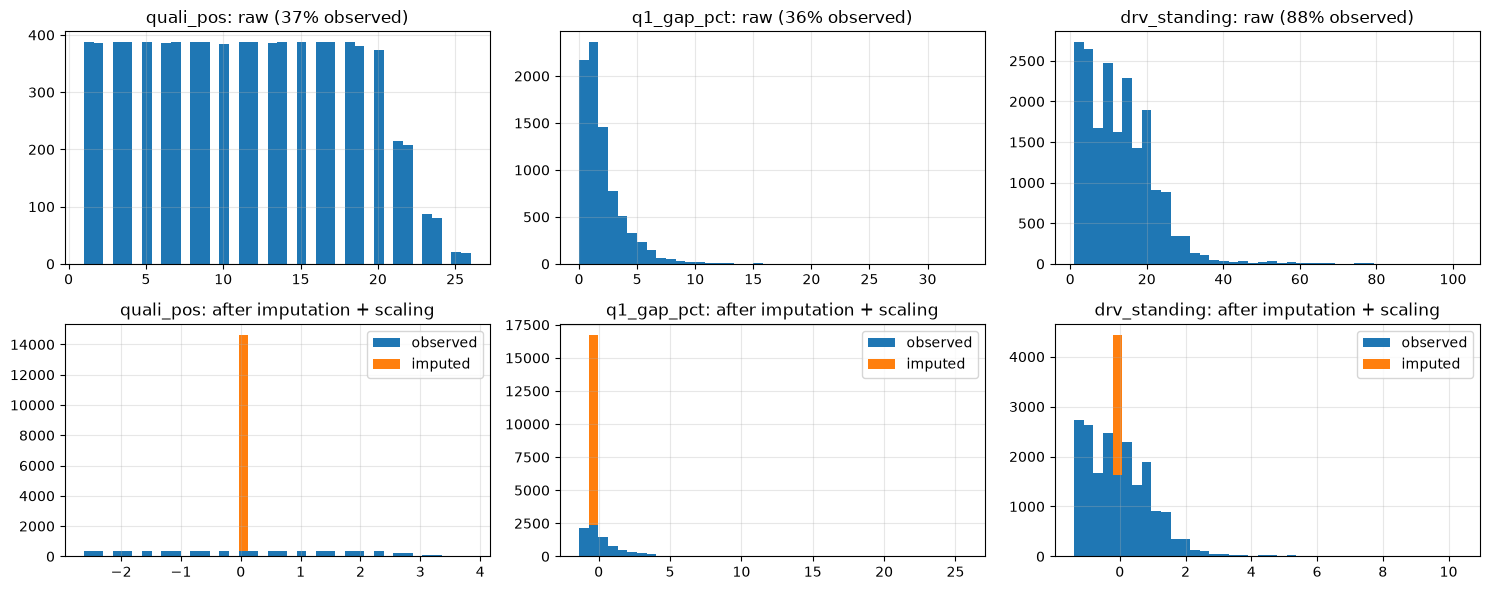

In [53]:
SHOW_PREP = ['quali_pos', 'q1_gap_pct', 'drv_standing']
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for i, col in enumerate(SHOW_PREP):
    observed = train_rows[col].notna()
    axes[0, i].hist(train_rows[col].dropna(), bins=40)
    axes[0, i].set_title(f'{col}: raw ({observed.mean():.0%} observed)')
    axes[1, i].hist([Z_train.loc[observed, col], Z_train.loc[~observed, col]], bins=40, stacked=True, label=['observed', 'imputed'])
    axes[1, i].set_title(f'{col}: after imputation + scaling')
    axes[1, i].legend()
plt.tight_layout()
save_fig('preprocessing_effect')
plt.show()

After preprocessing every feature has mean 0 and standard deviation 1, and no value is missing. The shape of the observed values does not change (scaling is linear). The imputed rows all sit on one value, the training median, which is the tall orange bar (63% of `quali_pos` and `q1_gap_pct` in train, 12% of `drv_standing`). The 7 indicator columns record which rows were filled, so a model can tell a real median value from a filled one.

### 9.3 Preprocessing-order experiments

Each experiment changes only the order (or scope) of one step and keeps everything else fixed: same rows, same features, same model, same validation windows.

**E1. Fit the imputer and scaler before or after splitting?** In the leaky order, the medians, means and standard deviations are computed on every row (train, validation and test) before splitting.

In [54]:
leaky_prep = make_preprocessor().fit(features[SELECTED])
leaky_table = pd.concat([features[['year', 'podium']], transform_to_frame(leaky_prep, features[SELECTED])], axis=1)
leaky_cols = [c for c in leaky_table.columns if c not in ('year', 'podium')]
compare({
    'split, then fit on train rows (correct)': score_windows(features, SELECTED),
    'fit on all rows, then split (leaky)': score_windows(leaky_table, leaky_cols, lambda: LogisticRegression(max_iter=2000)),
})

,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"split, then fit on train rows (correct)",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"fit on all rows, then split (leaky)",0.7392,0.7162,0.7339,0.7298,0.9377,0.0003,3/3


The leaky order scores higher in all three windows, but by only +0.0003, a twentieth of the noise level. The training rows (22,589) outnumber the validation and test rows (2,135), so adding them barely moves a median or a standard deviation. The order still matters: the leaky version uses statistics from the seasons it is evaluated on, and with a smaller training set or drifting features the gain would be larger and fake. **Decision: split first, fit on train only.**

**E2. Impute then scale, or scale then impute?**

In [55]:
def make_lr_scale_first():
    return make_pipeline(StandardScaler(), SimpleImputer(strategy='median', add_indicator=True), LogisticRegression(max_iter=2000))


scale_first = make_pipeline(StandardScaler(), SimpleImputer(strategy='median', add_indicator=True)).fit(train_rows[SELECTED])
Z_scale_first = transform_to_frame(scale_first, train_rows[SELECTED])
display(pd.DataFrame({
    'impute -> scale: mean': Z_train[SELECTED].mean(), 'impute -> scale: std': Z_train[SELECTED].std(),
    'scale -> impute: mean': Z_scale_first[SELECTED].mean(), 'scale -> impute: std': Z_scale_first[SELECTED].std(),
}).loc[lambda t: t['impute -> scale: std'].round(3) != t['scale -> impute: std'].round(3)].round(3))
compare({
    'impute -> scale (chosen)': score_windows(features, SELECTED),
    'scale -> impute': score_windows(features, SELECTED, make_lr_scale_first),
})

,impute -> scale: mean,impute -> scale: std,scale -> impute: mean,scale -> impute: std
quali_pos,-0.0,1.0,-0.036,0.608
q1_gap_pct,0.0,1.0,-0.167,0.616
drv_standing,-0.0,1.0,-0.015,0.936
con_standing,-0.0,1.0,-0.006,0.935
drv_podium_last,0.0,1.0,-0.016,0.989
drv_finish_last,-0.0,1.0,0.002,0.985
drv_career_podium,0.0,1.0,-0.014,0.988


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
impute -> scale (chosen),0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
scale -> impute,0.7389,0.7155,0.7329,0.7291,0.9366,-0.0004,0/3


The scores are tied (−0.0004, slightly lower ROC-AUC for scale → impute). The order does change the data: scaling first computes the mean and standard deviation on the observed values only, and the imputed rows are then all placed at the scaled median, so `quali_pos` ends with standard deviation 0.61 instead of 1 and a mean that is not 0. **Decision: impute, then scale**, so every model input is exactly standardised.

**E3. Build the form features before or after removing the non-starters?** In section 3.4 the non-starters were removed *before* the features were built, so form only counts races the driver actually started. The other order builds form from every entry, so a failed qualification counts as a race without a podium and with a last-place finish.

In [56]:
all_entries = entries[~is_indy]
features_before_filter = build_features(starters, n_form=N_FORM_FINAL, history=all_entries)
changed = (features_before_filter[FORM_FINAL].round(6) != features[FORM_FINAL].round(6)) & features[FORM_FINAL].notna()
print('Share of rows whose form values change:', changed.any(axis=1).mean().round(3),
      '| before 1995:', changed.any(axis=1)[features['year'] < 1995].mean().round(3),
      '| 2016-2021:', changed.any(axis=1)[features['year'].between(2016, 2021)].mean().round(3))
compare({
    'filter, then build features (chosen)': score_windows(features, SELECTED),
    'build features, then filter': score_windows(features_before_filter, SELECTED),
})

Share of rows whose form values change: 0.554 | before 1995: 0.836 | 2016-2021: 0.188


,2016-2017,2018-2019,2020-2021,mean PR-AUC,mean ROC-AUC,change in mean PR-AUC,better windows
"filter, then build features (chosen)",0.7391,0.7157,0.7337,0.7295,0.9377,0.0000,reference
"build features, then filter",0.7396,0.7172,0.7320,0.7296,0.9378,0.0001,2/3


The order changes the form values of 55% of the rows (84% before 1995, when many entries failed to qualify; 19% in 2016–21, because a non-starter also shifts the finishing percentile of everyone in that race), but the score does not move (+0.0001). It is a tie, decided by meaning: with the filter first, the form features describe races the driver actually started, which is what their names say. **Decision: filter, then build features.**

## 10. Hand-off to modeling

Everything sections 11–16 need is defined here. Those sections only read these names and never reassign them, so each section can be written and rerun on its own once Run All has reached this point. The modeling table is also written to `outputs/` (one row per driver–race, with the split and the selected features).

In [57]:
model_table = features[KEY + ['constructorId', 'circuitId', 'year', 'round', 'date', 'split', 'podium'] + SELECTED].copy()
model_table.to_csv(OUT_DIR / 'model_table.csv', index=False)
spec = {
    'target': 'podium',
    'features': SELECTED,
    'feature_groups': FEATURE_GROUPS,
    'form_window': N_FORM_FINAL,
    'split': {'train': '1950-2019', 'val': '2020-2021', 'test': '2022-2024'},
    'primary_metric': 'PR-AUC',
    'secondary_metric': 'ROC-AUC',
}
(OUT_DIR / 'feature_spec.json').write_text(json.dumps(spec, indent=2))

train = model_table[model_table['split'] == 'train']
val = model_table[model_table['split'] == 'val']
test = model_table[model_table['split'] == 'test']
X_train, y_train = train[SELECTED], train['podium']
X_val, y_val = val[SELECTED], val['podium']
X_test, y_test = test[SELECTED], test['podium']
print('X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)
print('Feature groups:', FEATURE_GROUPS)

X_train (22589, 9) | X_val (779, 9) | X_test (1356, 9)
Feature groups: {'grid': ['grid_pos', 'pit_lane_start'], 'qualifying': ['quali_pos', 'q1_gap_pct'], 'standings': ['drv_standing', 'con_standing'], 'driver form': ['drv_podium_last', 'drv_finish_last', 'drv_career_podium']}


In [58]:
def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'F1': f1_score(y_true, pred), 'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred)}


def best_threshold(y_true, proba):
    # threshold with the highest F1; call it on validation rows only
    thresholds = np.arange(0.05, 0.951, 0.01)
    scores = [f1_score(y_true, (proba >= t).astype(int)) for t in thresholds]
    return round(float(thresholds[int(np.argmax(scores))]), 2)


models_to_compare = {}   # name -> fitted model; sections 11-12 add their final models, section 13 compares them

**Contract for sections 11–16**

| Name | What it is |
| --- | --- |
| `model_table` | one row per driver–race (starters, no Indianapolis 500), ids, `split`, target `podium`, selected features |
| `SELECTED`, `FEATURE_GROUPS` | the 9 selected features and their 4 groups (groups are the units of the ablation) |
| `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test` | raw feature values (with `NaN`), split by season |
| `make_preprocessor()` | median imputation + missing indicators + standard scaling; put it in a `Pipeline` with the model so it is fitted on train only and the inference function can take raw values |
| `evaluate(y, proba, threshold)` | ROC-AUC, PR-AUC, F1, precision, recall |
| `best_threshold(y_val, proba_val)` | F1-optimal threshold, chosen on validation |
| `make_lr()` | the logistic regression used for every data decision; a natural baseline |
| `models_to_compare` | each modeling section adds its final model (anything with `predict_proba` on the raw `X_*`); section 13 scores all of them the same way |

Rules: fit on train; choose hyperparameters and the threshold on validation; score the test set once, at the end (section 13). The brief asks for "all five metrics": its table lists ROC-AUC, PR-AUC and F1, and we add precision and recall, which explain the F1. Tree models do not need the scaler and can take `NaN` directly; keep the same rows and features so the scores stay comparable.

## 11. Baseline and statistical models

*To do.* A baseline, at least two statistical models (e.g. logistic regression, random forest, gradient boosting), hyperparameter tuning on validation, how each model works and its limitations, and performance on train and validation. At least three distinct modeling attempts in the notebook in total.

## 12. Shallow neural network

*To do.* 1–2 hidden layers (Keras or PyTorch), same rows and features, inputs from `make_preprocessor()`, early stopping on validation, training curves, comparison against the baseline.

## 13. Model comparison

*To do.* One table: every model in `models_to_compare` × {train, validation, test} × {ROC-AUC, PR-AUC, F1, precision, recall}, at the threshold chosen on validation. State and justify the primary and secondary metric (our recommendation from section 7.1: PR-AUC primary, ROC-AUC secondary). Plot ROC and PR curves.

## 14. Feature-group ablation

*To do.* Retrain the chosen model once per group in `FEATURE_GROUPS`, each time without that group, and report the drop in validation PR-AUC / ROC-AUC / F1. Section 8.3 already shows the forward version made before training; the ablation is the after-training measurement the brief asks for.

## 15. Explainability (XAI)

*To do.* Global: permutation importance and SHAP. Local: one prediction explained with LIME and/or a SHAP waterfall. State explicitly that importance means the model relies on a feature, not that the feature causes podiums.

## 16. Inference function

*To do.* A function that takes one driver–race record (the values of `SELECTED`) and returns the podium probability and the 0/1 prediction at the chosen threshold. Demonstrate it on a complete record and on a record with missing values (for example no qualifying data); the imputer in `make_preprocessor()` handles the missing values.

## 17. Assumptions and limitations

**Assumptions** made in the data sections, each tested or justified where it is made:

| Assumption | Evidence | Section |
| --- | --- | --- |
| A `q1` time above 150% of pole is a data-entry error | one such time (1023% of pole); the next slowest is 145% | 3.1 |
| The car a driver started in is the one nobody else drove, otherwise the first listed row | 88 of the 91 rows not kept are cars another driver started | 3.3 |
| A driver credited with a podium in a shared car has `podium = 1` | official classification (rule D) | 3.3 |
| A driver with a grid slot or at least one completed lap is on the starting list at the cutoff | entries with neither have no podium and are mostly `F` (failed to qualify) / `W` (withdrawn) | 3.4 |
| `grid = 0` with laps is a pit-lane start, placed behind the last car | 72 rows, all 2015–2024; the three encodings score the same | 3.4, 9.1 |
| The Indianapolis 500 is a separate population | 96% of its drivers never raced another championship race | 3.4 |
| Known at the cutoff: the grid, the qualifying result, the standings after the previous round | the cutoff is after qualifying; checked automatically for round 1 and for form | 6.1, 6.3 |
| Nationality → country: dual nationalities take the first, `East German` → Germany | hand-made map, printed in full | Q2 |
| Ambiguous statuses (bare `Retired`, tyre, wing, damage, ...) are not mechanical | counting them as mechanical keeps the same leaders | Q3 |
| One `constructorId` / `circuitId` is one team / circuit (renamed teams and changed layouts are not merged) | the dataset has no lineage table; stated next to the answers | Q1, Q3 |
| A score difference below 2 × the spread from dropping 1% of training rows is noise | measured: 0.005 (LR), 0.011 (tree model) | 7.1 |

**Limitations** on the data and feature side (to be completed with the modeling limitations):

- **Qualifying coverage drift.** No qualifying data before 1994 and only 6–59% coverage in 1996–2002, so 63% of the training rows have imputed qualifying features. The missing indicators let a model treat those rows differently, but the qualifying signal itself is learned from 37% of the training rows.
- **Era sensitivity.** The grid-to-podium relationship and reliability changed a lot (pole to podium 53% in 1950–69, 81% since 2014; about half of the starters finished before 2000, 86% in the 2020s). Training on every season mixes these eras; the test seasons are a new regulation era.
- **Renamed teams reset history.** Constructor form and standings follow `constructorId`, so a renamed team (Renault → Alpine, Toro Rosso → AlphaTauri → RB) starts with no form.
- **Manual mappings.** The status groups (question 3) and the nationality → country map (question 2) are judgement calls, documented in the tables above; question 3 includes a sensitivity check.
- **Small validation windows.** Each two-season window is about 40 races, so differences below about 0.01 PR-AUC are within noise. Several of our choices were ties and were decided on domain grounds; this is stated next to each one.
- **Not used.** Sprint results (no training rows), pit stops and lap times (in-race), and four candidate groups whose gain was within the noise level (constructor form, experience, field size, home; 8.3).